# Notebook 8 (v2) — full-brain release: privacy–utility frontier

Implements `SPEC_NB8.md` (v2) and the 2026-10-23 review actions. Settled mechanism: `z = Σ aₘVₘ`,
hard **per-eigenmode-max** bar `bₘ = maxᵢ|Dᵢ·Vₘ|`, all modes noised (`k_noise=r`), sampled by the
rejection-free **direct sampler**. Attack: known-background **projection** membership advantage,
whole-brain. Engine: `release_noise.py` (Tier-3); frozen `mode_eigen_mech.py`, `privacy_harness.py`,
`inference_eval.py` untouched. **Empirical privacy only — no formal ε.**

**Targets** (all three evaluated): `worst` (real subject least covered by the L2 bar — the
discriminating case), `ksigma` (synthetic mean+2σ outlier), `istar` (the subject the L2 bar is built
on — a covered control). **Advantage** = `TPR − FPR` (chance = 0; see §1). **Acceptable** = upper 95 %
CI of advantage ≤ **ε = 0.1**.

## 0 · Setup, frozen check, configuration

In [1]:
# CAP BLAS THREADS BEFORE importing numpy — else every tiny per-patch SVD spawns ~cpu_count threads.
import os
for _v in ("OMP_NUM_THREADS","MKL_NUM_THREADS","OPENBLAS_NUM_THREADS","NUMEXPR_NUM_THREADS","VECLIB_MAXIMUM_THREADS"):
    os.environ[_v] = "1"
import sys, hashlib, time, numpy as np, pandas as pd, matplotlib.pyplot as plt
for c in [".", "work", os.path.expanduser("~/harness")]:
    if os.path.exists(os.path.join(c, "privacy_harness.py")): sys.path.insert(0, c); break
import privacy_harness as ph, mode_eigen_mech as me, tiling as T
import full_release_attacks as fra, release_noise as R
import io as _io, pickle
# Force pandas' lazy CSV/formatting imports NOW (fail fast at the top, not after an hour-long sweep —
# these lazy-import on a network-mounted venv and have failed mid-run before). Cache uses pickle anyway.
try:
    import pandas.io.formats.csvs, stack_data; pd.DataFrame({"_":[0]}).to_csv(_io.StringIO())
    print("env import check: OK")
except Exception as _e:
    print("WARNING env import check FAILED:", repr(_e), "-- repair the venv before long runs")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
FROZEN = {"privacy_harness.py": "f03e766b265b4b0b253ce3a8eb94cb53ea76662544ea0b1b9db102f8f29015b4",
          "inference_eval.py":  "0bd08830469858a9332a5cfddc6c332a894dc318b09efda42a9ba8fa6c2b2018"}
for f, h in FROZEN.items():
    p = next((os.path.join(c, f) for c in [".", "work", os.path.expanduser("~/harness")]
              if os.path.exists(os.path.join(c, f))), None)
    if p: print(f"  {f}: {'OK' if hashlib.sha256(open(p,'rb').read()).hexdigest()==h else 'CHANGED!'}")

env import check: OK
  privacy_harness.py: OK
  inference_eval.py: OK


In [2]:
USE_OASIS = True                 # False -> portable phantom + reduced grid (end-to-end validation)
BLEND     = "pou_energy"
EPS       = 0.10                 # acceptable-advantage criterion: upper 95% CI of advantage <= EPS
from joblib import Parallel, delayed
SEED = 0
CKPT_DIR = os.path.abspath("nb8_ckpt")      # §3 frontier is cached here; delete to force a recompute

if USE_OASIS:
    N          = 40
    PATCHES    = {"5x5x5": (5,5,5), "single": "single"}   # single vs "multiple patches"; neighbours omitted
    OVERLAPS   = [0.0, 0.25, 0.5]
    STATS      = ["mean", "median", "variance"]
    TARGETS    = ["worst", "ksigma", "istar"]
    SCALES     = [1, 2, 3, 4, 6, 8, 10, 12, 20, 30, 40, 50, 60, 70, 80, 90, 100]   # advantage at all of these
    UTIL_SCALES= [1, 2, 4, 8, 20, 40, 70, 100]     # utility (expensive field sampling) at a coarser subset
    INF_SCALES = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]                        # §5 fine integer grid (keeps 0)
    KCHECKS    = [8, 16, 26, None]          # None = r (full-rank policing)
    N_SWEEP    = [20, 40, 60, 80, 100]
    REP_PATCH  = "5x5x5"; REP_SCALE = 8; KC_SCALES = [1, 12]
    ISO_SIZES  = [(5,5,5)]
    N_TRIALS, N_REL, N_MC = 4000, 50, 200
else:
    N          = 30
    PATCHES    = {"5x5x5": (5,5,5), "single": "single"}
    OVERLAPS   = [0.5]
    STATS      = ["mean", "variance"]
    TARGETS    = ["worst", "ksigma", "istar"]
    SCALES     = [1, 2, 4, 8, 20, 60, 100]
    UTIL_SCALES= [1, 4, 8, 20, 100]
    INF_SCALES = [0, 1, 4, 8, 12]
    KCHECKS    = [8, None]
    N_SWEEP    = [15, 20, 30]
    REP_PATCH  = "5x5x5"; REP_SCALE = 8; KC_SCALES = [1, 12]
    ISO_SIZES  = [(5,5,5)]
    N_TRIALS, N_REL, N_MC = 1500, 20, 80

N_JOBS = 20
PKW    = dict(n_jobs=N_JOBS, verbose=10, inner_max_num_threads=1)
NB_BUILD  = N_JOBS                                   # threads for parallel per-patch builds (serial-outer sections)
REF_PATCH = "7x7x7" if "7x7x7" in PATCHES else REP_PATCH   # cheap saturated patched reference (~8x fewer patches than 5³)
BLENDS    = ["average", "pou", "pou_energy"]          # Exp A
EXPB_SIZE = (5,5,5)                                   # Exp B patch size
EXPB_K    = ([1,2,4,8,16,32,64] if USE_OASIS else [1,2,4,8])
EXPC_PATCHES = [p for p in ["single","5x5x5","7x7x7"] if p in PATCHES or p=="single"]  # Exp C
REP_PATCH_PS = PATCHES[REP_PATCH]
PCOL = {"3x3x3":"#4575b4","5x5x5":"#91bfdb","7x7x7":"#fc8d59","single":"#d73027"}
TCOL = {"worst":"#d73027","ksigma":"#1f78b4","istar":"#33a02c"}
print(f"patches={list(PATCHES)} overlaps={OVERLAPS} stats={STATS} targets={TARGETS}")
print(f"scales={SCALES} | N={N} n_trials={N_TRIALS} n_rel={N_REL} n_mc={N_MC} n_jobs={N_JOBS} eps={EPS}")

patches=['5x5x5', 'single'] overlaps=[0.0, 0.25, 0.5] stats=['mean', 'median', 'variance'] targets=['worst', 'ksigma', 'istar']
scales=[1, 2, 3, 4, 6, 8, 10, 12, 20, 30, 40, 50, 60, 70, 80, 90, 100] | N=40 n_trials=4000 n_rel=50 n_mc=200 n_jobs=20 eps=0.1


In [3]:
# substrate: OASIS gray-matter maps (whole volume) or a portable phantom
def gm_mask(volumes):
    from scipy import ndimage as ndi
    gm = np.asarray(volumes, float).mean(0); fin = np.isfinite(gm) & (gm > 0)
    try:
        from skimage.filters import threshold_otsu; thr = float(threshold_otsu(gm[fin]))
    except Exception: thr = float(np.percentile(gm[fin], 60))
    m = ndi.binary_fill_holes(gm > thr); lab, n = ndi.label(m)
    if n > 1:
        sz = ndi.sum(np.ones_like(lab), lab, range(1, n+1)); m = lab == (1 + int(np.argmax(sz)))
    return m & np.isfinite(gm)
if USE_OASIS:
    try:
        SUB = T.load_oasis_volumes(n=max(N + 20, 120)); VOLS = np.asarray(SUB["volumes"])
        MASK = gm_mask(VOLS); SUBSTRATE = "OASIS gray-matter maps"
    except Exception as e:
        USE_OASIS = False; print("OASIS unavailable ->", repr(e))
if not USE_OASIS:
    SUB = T.make_phantom(shape=(16,16,14), M=2*N+20, N=N, seed=0)
    VOLS = SUB["volumes"]; MASK = SUB["mask"]; SUBSTRATE = "synthetic phantom"
COHORT = VOLS[:N]
try:
    import skimage; SSIM_OK = True
except Exception:
    SSIM_OK = False
print(f"substrate: {SUBSTRATE} | volumes {VOLS.shape} | in-mask voxels p = {int(MASK.sum())} | r = N-1 = {N-1}")
print(f"scikit-image present: {SSIM_OK} (SSIM column is NaN without it)")
TGT = {st: R.select_targets(COHORT, MASK, st) for st in STATS}
for st in STATS:
    print(f"  {st:>8}: worst #{TGT[st]['worst']}  istar #{TGT[st]['istar']}  (ksigma = synthetic mean+2sd)")

[fetch_oasis_vbm] Dataset directory found: /users/lukasschuler/nilearn_data/oasis1
substrate: OASIS gray-matter maps | volumes (120, 91, 109, 91) | in-mask voxels p = 136955 | r = N-1 = 39
scikit-image present: True (SSIM column is NaN without it)
      mean: worst #19  istar #37  (ksigma = synthetic mean+2sd)
    median: worst #37  istar #0  (ksigma = synthetic mean+2sd)
  variance: worst #4  istar #37  (ksigma = synthetic mean+2sd)


### The attack metric and the acceptance criterion (read once)

The attacker projects the release onto the known influence direction `Δ = g_in − g_out`, picks a
threshold by Youden's J on a held-out split, and reports **advantage = TPR − FPR** on a disjoint test
split (frozen `_threshold_youden` / `_adv_at`), with a bootstrap 95 % CI (`_adv_ci`).

- **Range** [−1, 1]; **0 = chance**, 1 = perfect membership inference. It equals `2·(balanced
  accuracy) − 1`, so advantage 0.2 ↔ balanced accuracy 0.60.
- It is **not AUC** (threshold-free, chance 0.5) and **not raw accuracy** (chance 0.5). Those names are
  avoided below; only this TPR−FPR *advantage* is reported.
- **Estimator floor:** at finite `n_trials` the advantage of a *perfectly private* release is not
  exactly 0 (sampling noise in the threshold fit); the §1 huge-noise control measures this floor. We
  therefore judge privacy by the **upper 95 % CI**, not the point estimate, and call a configuration
  acceptable only when **adv_hi ≤ ε = 0.1** (balanced accuracy ≤ 0.55) at its operating scale.

## 1 · Attack controls + oracle

*Plot/notes below:* the control runs the attack on the cheap whole-brain `single` release at two
extreme noise levels — near-zero noise (expect advantage ≈ 1, perfect identification) and overwhelming
noise (expect advantage ≈ 0 = the estimator's chance floor). The oracle checks that at `k_check = 0`
(no bar) the direct sampler is exactly `N(0, scale²·Cov)`: the projected-score variance must equal
`scale²·Σₘ λₘ (Vₘ·Δ)²` in closed form.

In [4]:
# control + oracle on the cheap `single` release (substrate-agnostic sanity, 1 SVD)
gi, go, ri, ro, d = R.two_worlds(COHORT, MASK, "mean", "single", 0.5, BLEND, TGT["mean"]["worst"])
rng = np.random.default_rng(SEED)
ctrl = R.advantage_sweep(gi, go, ri, ro, d, [0.02, 1e4], None, N_TRIALS, rng)
print(f"control: near-zero noise adv={ctrl[0]['advantage']:.3f} (expect ~1);  "
      f"huge noise adv={ctrl[1]['advantage']:.3f} ci={tuple(round(x,3) for x in ctrl[1]['adv_ci'])} "
      f"(expect ~0 = chance floor at n_trials={N_TRIALS})")
sg = ri
dvec = (gi - go); dproj = sg.V.T @ dvec
var_analytic = float(np.sum(sg.lam * dproj**2))
emp = sg.project_scores(dvec, 20000, np.random.default_rng(1), scale=1.0, k_check=0)
print(f"oracle k_check=0: var(projected) empirical={emp.var():.4g}  analytic={var_analytic:.4g}  "
      f"ratio={emp.var()/var_analytic:.3f} (expect ~1)")

control: near-zero noise adv=1.000 (expect ~1);  huge noise adv=0.219 ci=(0.184, 0.245) (expect ~0 = chance floor at n_trials=4000)
oracle k_check=0: var(projected) empirical=0.4191  analytic=0.418  ratio=1.003 (expect ~1)


## 1b · Motivation — why we changed the mechanism

**(A) direct sampler ≡ rejection mechanism.** Accepted and tail-filled (fallback) draws come from the
identical folded-tail law, so the released noise — hence privacy and utility — does not depend on the
fallback rate; we drop rejection for a rejection-free sampler. **(B) per-eigenmode-max vs L2 coverage.**
The L2 bar polices one subject `i*`; the per-mode-max bar polices the worst subject in *every* mode.

*Figure 1b-A — two panels.* **Left:** entry-wise output covariance of the direct sampler (y) vs
the frozen rejection sampler (x), on one 5³ patch (both use the same L2 bar); points on the dashed
`y = x` line ⇒ identical output law; the title gives the Frobenius relative difference. **Right:** the
released noise's **projected-score standard deviation** (y, the output magnitude along a fixed probe
direction) as a function of the **fallback rate** (x), swept across the **full 0→1 range by varying the
noise scale**. Red = rejection sampler, green = direct sampler. The two lie on top of each other at
every fallback rate ⇒ the output does not depend on fallback (so rejection can be dropped). *Why one
policed mode here:* with all r modes policed the joint fallback rate is ≈1 at every realistic scale
(the x-axis could not reach 0); policing a single mode lets the fallback rate span 0→1, and the
per-mode equivalence is identical at k_check = r.

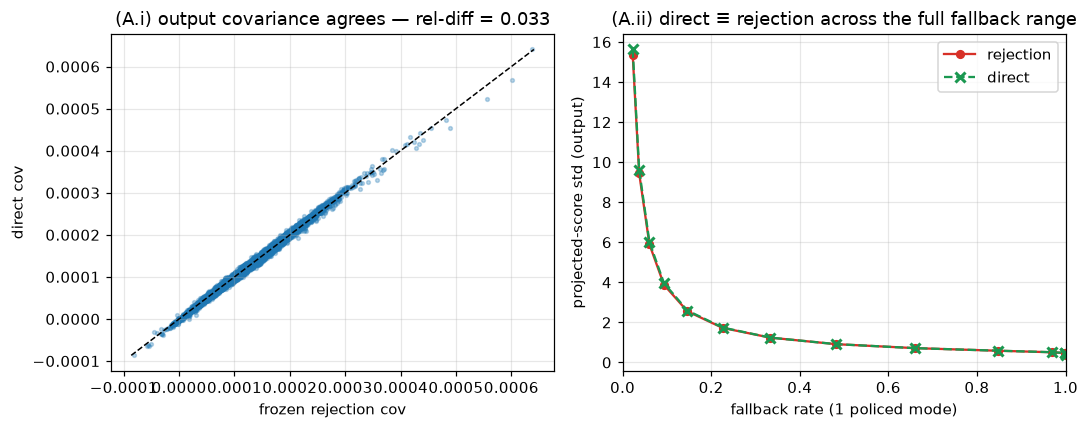

[A] covariance rel-diff 0.033 (<0.08 OK); fallback spanned 0.02→1.00; direct-vs-rejection output differ by at most 2.2% across that range


In [5]:
src = ph.ArrayBlockSource(VOLS, MASK, block_shape=(5,5,5), N=N, seed=SEED)
pool = src.sample(N, np.random.default_rng(0)).reshape(N,5,5,5)
yv, Dv, Sv = ph.loo_artifacts(pool, ph.pipeline_mean); r = N - 1
fm = me.mech_mode_eigen(yv, Dv, Sv, scale=3.0, k_check=r, max_draws=600, keep_modes=True)
Zf = np.array([fm.sample(np.random.default_rng(1000+i)) for i in range(4000)])
V, lam, bar_l2, _ = R.mode_bundle(Dv.reshape(N,-1), "l2")
Zd = R.draw_coeffs(lam, bar_l2, 3.0, r, 4000, np.random.default_rng(7)) @ V.T
cf, cd = np.cov(Zf.T), np.cov(Zd.T); iu = np.triu_indices(cf.shape[0])
reldiff = np.linalg.norm(cf - cd) / np.linalg.norm(cf)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(cf[iu], cd[iu], s=6, alpha=.3, color="#1f78b4")
lim = [min(cf[iu].min(), cd[iu].min()), max(cf[iu].max(), cd[iu].max())]
ax[0].plot(lim, lim, "k--", lw=1); ax[0].set_xlabel("frozen rejection cov"); ax[0].set_ylabel("direct cov")
ax[0].set_title(f"(A.i) output covariance agrees — rel-diff = {reldiff:.3f}")
dirp = yv.reshape(-1)
from scipy.stats import norm as _norm
def _fb1(scl):                       # fallback (reject) rate with ONE policed mode = P(|a| < bar)
    s = scl * np.sqrt(max(lam[0], 0.0)); return float(2 * _norm.cdf(bar_l2[0] / s) - 1) if s > 0 else 1.0
pts = []
for scl in [0.3, 0.5, 0.8, 1.2, 1.8, 2.7, 4.0, 6.0, 9.0, 14.0, 22.0, 34.0, 55.0, 90.0]:
    fmk = me.mech_mode_eigen(yv, Dv, Sv, scale=scl, k_check=1, max_draws=4000, keep_modes=True)
    srej = float((np.array([fmk.sample(np.random.default_rng(i)) for i in range(1200)]) @ dirp).std())
    sdir = float((R.draw_coeffs(lam, bar_l2, scl, 1, 1200, np.random.default_rng(2)) @ V.T @ dirp).std())
    pts.append((_fb1(scl), srej, sdir))
pts.sort(); fb = [p[0] for p in pts]; srej = [p[1] for p in pts]; sdir = [p[2] for p in pts]
ax[1].plot(fb, srej, "o-", color="#d73027", label="rejection", ms=5)
ax[1].plot(fb, sdir, "x--", color="#1a9850", label="direct", ms=7, mew=2)
ax[1].set_xlim(0, 1); ax[1].set_xlabel("fallback rate (1 policed mode)")
ax[1].set_ylabel("projected-score std (output)")
ax[1].set_title("(A.ii) direct ≡ rejection across the full fallback range"); ax[1].legend()
plt.tight_layout(); plt.show()
_maxrel = max(abs(a/b - 1) for a, b in zip(sdir, srej) if b > 0)
print(f"[A] covariance rel-diff {reldiff:.3f} (<0.08 OK); fallback spanned {min(fb):.2f}→{max(fb):.2f}; "
      f"direct-vs-rejection output differ by at most {_maxrel*100:.1f}% across that range")

*Figure 1b-B — coverage heatmap (statistic = mean).* Each cell is one **(subject, mode)** pair:
**green = covered** (the bar is at least as large as that subject's footprint in that mode,
`|Dᵢ·Vₘ| ≤ bₘ`, so the noise is guaranteed to mask it), **red = exposed** (`|Dᵢ·Vₘ| > bₘ`). Rows =
the N subjects, columns = the r eigenmodes (ordered by decreasing energy). **Left = L2 bar** (polices
only the single subject `i*`, so other subjects show red cells — gaps the noise is *not* guaranteed to
cover); **right = per-mode-max bar** (polices the worst subject in every mode, so every cell is green =
100% coverage by construction). This is exactly why we switched the bar. The table underneath gives the
covered fraction for all statistics.

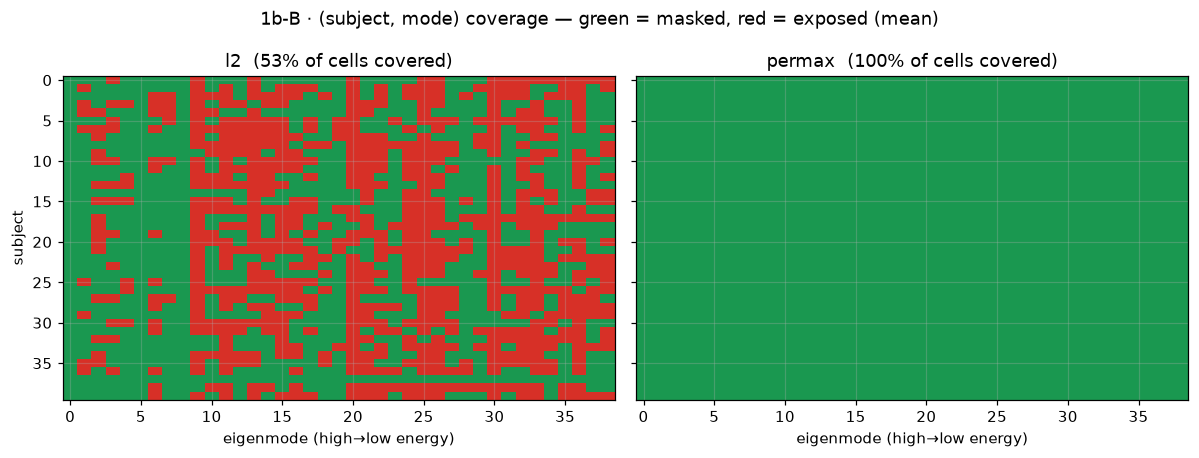

    stat    bar  coverage(all pairs)  coverage(worst subject)
    mean     l2                0.531                    0.359
    mean permax                1.000                    1.000
  median     l2                0.515                    0.333
  median permax                1.000                    1.000
variance     l2                0.385                    0.256
variance permax                1.000                    1.000


In [6]:
sg = R.build_release(COHORT, MASK, "mean", "single"); proj = sg._proj
istar = int(np.argmax(np.linalg.norm(proj, axis=1)))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
from matplotlib.colors import ListedColormap
cmap = ListedColormap(["#d73027", "#1a9850"])   # 0=exposed(red), 1=covered(green)
for a, bk in zip(axes, ["l2", "permax"]):
    bar = np.abs(proj).max(0) if bk == "permax" else np.abs(proj[istar])
    covered = (np.abs(proj) <= bar[None, :]).astype(int)      # (N subjects, r modes)
    a.imshow(covered, aspect="auto", cmap=cmap, vmin=0, vmax=1, interpolation="nearest")
    a.set_title(f"{bk}  ({100*covered.mean():.0f}% of cells covered)")
    a.set_xlabel("eigenmode (high→low energy)")
axes[0].set_ylabel("subject")
fig.suptitle("1b-B · (subject, mode) coverage — green = masked, red = exposed (mean)")
plt.tight_layout(); plt.show()
covsum = {}
for st in STATS:
    p = R.build_release(COHORT, MASK, st, "single")._proj
    istr = int(np.argmax(np.linalg.norm(p, axis=1)))
    for bk in ["l2", "permax"]:
        bar = np.abs(p).max(0) if bk == "permax" else np.abs(p[istr])
        c = (np.abs(p) <= bar[None, :]); covsum[(st, bk)] = (float(c.mean()), float(c.mean(1).min()))
print(pd.DataFrame([(st, bk, round(m,3), round(mn,3)) for (st, bk), (m, mn) in covsum.items()],
                   columns=["stat","bar","coverage(all pairs)","coverage(worst subject)"]).to_string(index=False))

## 2 · Per-config baseline (at the operating scale)

*Table below.* Quick sanity on the **cheap** configs (single + 7³ at each overlap): membership
advantage for **all three targets** at the operating scale, with coverage, patch count and the utility
panel (rel-MSE, Spearman, SSIM). The FULL per-config grid incl. 3³/5³ lives in §3 (cached), so we don't
rebuild those 36k-patch releases here. advantage ↓ better; rel-MSE ↓ better; Spearman, SSIM ↑ better.

In [7]:
def _baseline(nm, ps, ov):
    st = "mean"; rel_full = R.build_release(COHORT, MASK, st, ps, (0.5 if ov is None else ov), BLEND,
                                            n_build_jobs=NB_BUILD)
    row = dict(patch=nm, overlap=("-" if ov is None else ov), n_patches=rel_full.n_patches,
               coverage=round(rel_full.coverage()["overall"], 3))
    for tg in TARGETS:
        gi, go, ri, ro, dv = R.two_worlds(COHORT, MASK, st, ps, (0.5 if ov is None else ov), BLEND,
                                          TGT[st][tg], rel_full=(None if tg=="ksigma" else rel_full),
                                          n_build_jobs=NB_BUILD)
        a = R.advantage_sweep(gi, go, ri, ro, dv, [REP_SCALE], None, N_TRIALS, np.random.default_rng(1))[0]
        row[f"adv_{tg}"] = round(a["advantage"], 3)
    u = R.release_utility(rel_full, REP_SCALE, None, np.random.default_rng(2), n_rel=N_REL)
    row.update(rel_mse=round(u["rel_mse"],4), spearman=round(u["spearman"],3), ssim=round(u["ssim"],3))
    return row
cfgs = [("single", "single", None)] + [(REF_PATCH, PATCHES[REF_PATCH], ov) for ov in OVERLAPS]
BASE = pd.DataFrame([_baseline(nm, ps, ov) for nm, ps, ov in cfgs])     # sequential + parallel build
print(f"baseline @ scale={REP_SCALE}, statistic=mean (cheap configs; full grid in §3):")
print(BASE.to_string(index=False))

baseline @ scale=8, statistic=mean (cheap configs; full grid in §3):
 patch overlap  n_patches  coverage  adv_worst  adv_ksigma  adv_istar  rel_mse  spearman  ssim
single       -          1       1.0      0.445       0.376      0.270   0.0068     0.958 0.992
 5x5x5     0.0       2075       1.0      0.999       1.000      0.999   0.0066     0.955 0.992
 5x5x5    0.25       3314       1.0      0.999       1.000      1.000   0.0067     0.955 0.992
 5x5x5     0.5      17560       1.0      0.999       0.999      0.995   0.0067     0.955 0.992


## 3 · Frontier sweep — scale × patch{incl. single} × overlap × statistic (k_check = r)

Every config swept over the same scales, same whole-brain projection attack, same utility panel;
modes/bar built once per (patch, overlap, statistic), scale applied at sample time. Cached to
`nb8_ckpt/RES.csv` — delete that folder to recompute. **Note:** a cache produced with two targets is
loaded as-is; plots below adapt to whichever targets are present (add `istar` by recomputing).

In [9]:
import os
_bad = os.path.join(CKPT_DIR, "RES.pkl")
if os.path.exists(_bad):
    os.remove(_bad)
    print("removed the None-containing RES.pkl — now re-run the §3 sweep cell to recompute")
else:
    print("no RES.pkl found; just run the §3 sweep cell")

removed the None-containing RES.pkl — now re-run the §3 sweep cell to recompute


In [10]:
t0 = time.time()
CFGS = [(nm, ps, (None if ps=="single" else ov))
        for nm, ps in PATCHES.items() for ov in (OVERLAPS if ps!="single" else [None])]
os.makedirs(CKPT_DIR, exist_ok=True)
_ckpt = os.path.join(CKPT_DIR, "RES.pkl"); _raw = os.path.join(CKPT_DIR, "out_raw.pkl")
RES = None
if os.path.exists(_ckpt):
    _c = pickle.load(open(_ckpt, "rb"))
    _stale = (not set(SCALES).issubset(set(_c.scale.unique()))) or (not set(PATCHES).issubset(set(_c.patch.unique())))
    if _stale:
        print("cached frontier is STALE (scales or patches changed) -> recomputing. Delete nb8_ckpt/ to force anytime.")
    else:
        RES = _c
        print(f"LOADED cached frontier: {_ckpt} ({len(RES)} rows, targets={sorted(RES.target.unique())}, "
              f"scales={sorted(RES.scale.unique())}) -- skipping the sweep.")
if RES is None:
    print(f"{len(CFGS)} configs x {len(STATS)} stats = {len(CFGS)*len(STATS)} parallel jobs")
    def _config_job(nm, ps, ov, st):
        ovv = 0.5 if ov is None else ov; rng = np.random.default_rng(hash((nm, ov, st)) % 2**31)
        rel_full = R.build_release(COHORT, MASK, st, ps, ovv, BLEND)
        cov = rel_full.coverage()["overall"]; npat = rel_full.n_patches; ovs = "-" if ov is None else ov
        urows = []
        for sc in UTIL_SCALES:                       # utility at a coarse subset (field sampling is the cost)
            u = R.release_utility(rel_full, sc, None, rng, n_rel=N_REL)
            urows.append(dict(patch=nm, overlap=ovs, stat=st, scale=sc, rel_mse=u["rel_mse"],
                              spearman=u["spearman"], ssim=u["ssim"], nc_gap=u["neighbour_corr_gap"]))
        arows = []
        for target in TARGETS:
            gi, go, ri, ro, dv = R.two_worlds(COHORT, MASK, st, ps, ovv, BLEND, TGT[st][target],
                                              rel_full=(None if target == "ksigma" else rel_full))
            for rw in R.advantage_sweep(gi, go, ri, ro, dv, SCALES, None, N_TRIALS, rng):
                arows.append(dict(patch=nm, overlap=ovs, stat=st, target=target, scale=rw["scale"],
                                  advantage=rw["advantage"], adv_lo=rw["adv_ci"][0],
                                  adv_hi=rw["adv_ci"][1], coverage=cov, n_patches=npat))
        return arows, urows
    jobs = [(nm, ps, ov, st) for (nm, ps, ov) in CFGS for st in STATS]
    out = Parallel(**PKW)(delayed(_config_job)(nm, ps, ov, st) for nm, ps, ov, st in jobs)
    try:                                              # capture the expensive compute IMMEDIATELY, before any fragile op
        pickle.dump(out, open(_raw, "wb")); print(f"raw job results saved -> {_raw}")
    except Exception as _e:
        print("raw-save warning:", repr(_e))
    ADV = pd.DataFrame([r for a, _ in out for r in a]); UTL = pd.DataFrame([r for _, u in out for r in u])
    RES = ADV.merge(UTL, on=["patch","overlap","stat","scale"], how="left")
    try:
        pickle.dump(RES, open(_ckpt, "wb"))
        print(f"sweep done in {time.time()-t0:.0f}s | rows: {len(RES)} | cached -> {_ckpt}")
    except Exception as _e:
        print("CACHE SAVE FAILED:", repr(_e),
              "\nRES is SAFE in memory. Save it yourself: import pickle; pickle.dump(RES, open('nb8_ckpt/RES.pkl','wb'))")
RES["overlap"] = RES["overlap"].astype(str)
TGTS_RES = [t for t in TARGETS if t in set(RES.target)]       # targets actually present in RES
def _ov05(df): return df[df.overlap.astype(str).isin(["-", "0.5"])]

4 configs x 3 stats = 12 parallel jobs


[Parallel(n_jobs=20)]: Using backend LokyBackend with 20 concurrent workers.
[Parallel(n_jobs=20)]: Done   1 tasks      | elapsed:  1.5min
[Parallel(n_jobs=20)]: Done   3 out of  12 | elapsed:  2.3min remaining:  6.8min
[Parallel(n_jobs=20)]: Done   5 out of  12 | elapsed: 10.8min remaining: 15.1min
[Parallel(n_jobs=20)]: Done   7 out of  12 | elapsed: 15.8min remaining: 11.3min
[Parallel(n_jobs=20)]: Done   9 out of  12 | elapsed: 17.1min remaining:  5.7min


raw job results saved -> /indirect/student/lukasschuler/DP_project/wp15/infrastructure/privacy_dev/nb8_ckpt/out_raw.pkl
sweep done in 4973s | rows: 612 | cached -> /indirect/student/lukasschuler/DP_project/wp15/infrastructure/privacy_dev/nb8_ckpt/RES.pkl


[Parallel(n_jobs=20)]: Done  12 out of  12 | elapsed: 82.9min finished


*Figure 3-1.* Membership **advantage vs scale** (log x, now extended to 100 so the curves' approach
to the target is visible). **Rows = targets** (worst/ksigma/istar), **columns = statistics**; one line
per config — 5³ patched (overlap 0.5) vs whole-brain `single` (red). Dotted line at 0 = chance; dashed
line = ε (the acceptance target); shaded band = 95 % CI. Lower is more private.

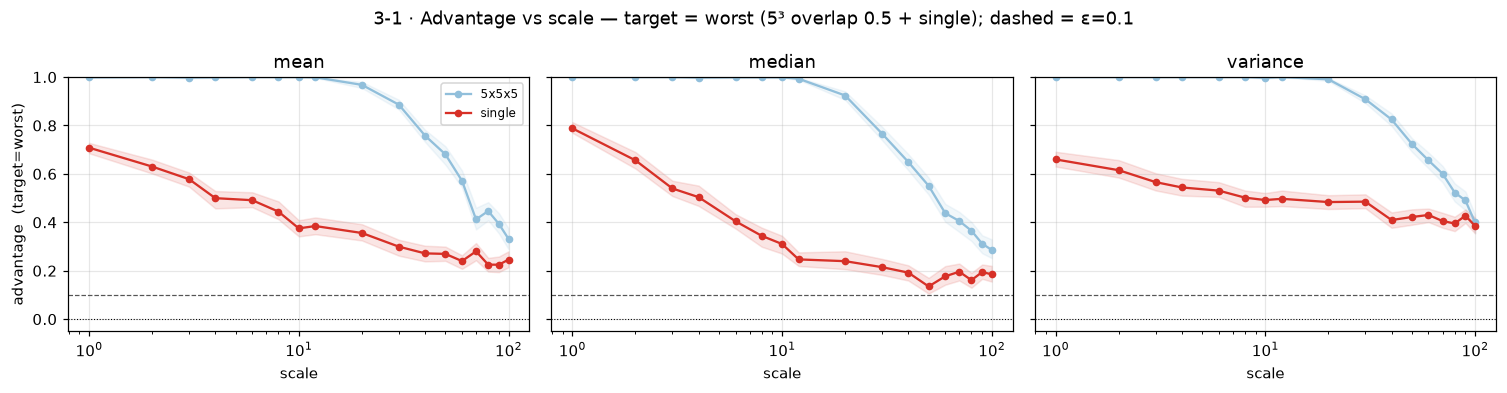

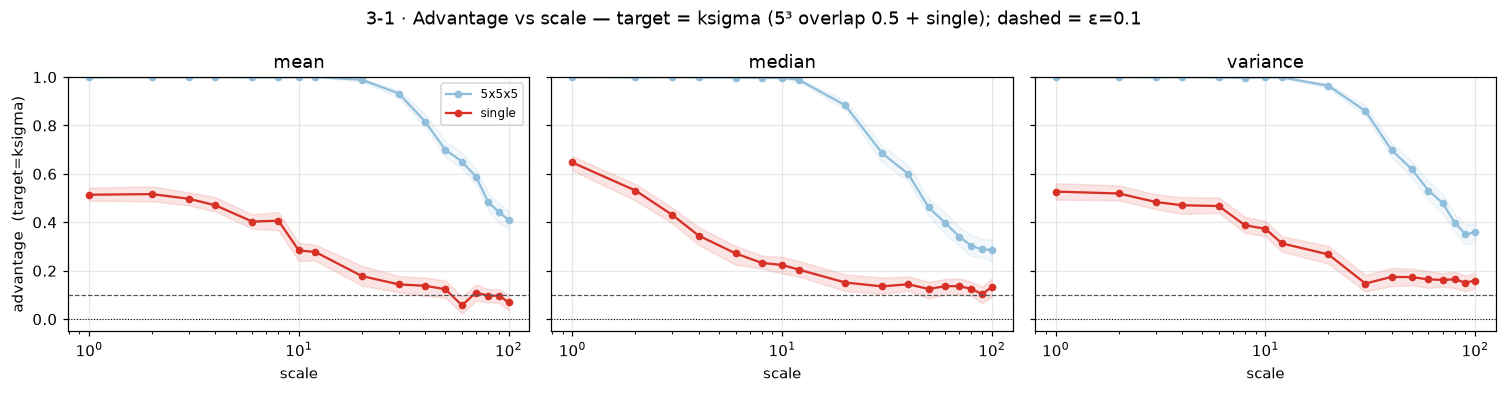

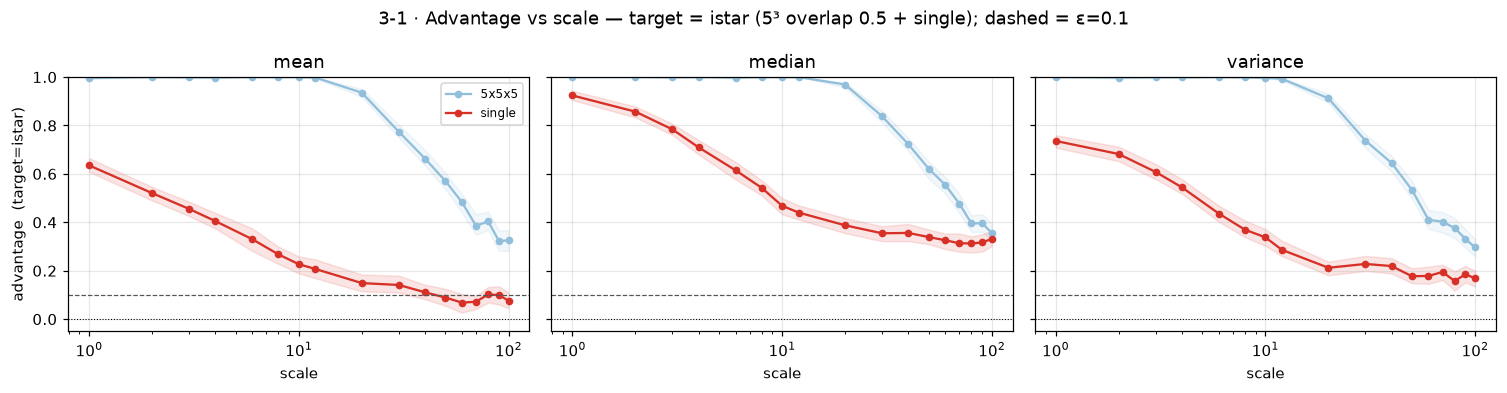

In [11]:
for TG in TGTS_RES:
    fig, axes = plt.subplots(1, len(STATS), figsize=(4.6*len(STATS), 3.6), squeeze=False, sharey=True)
    for a, st in zip(axes[0], STATS):
        sub = _ov05(RES[(RES.stat==st) & (RES.target==TG)])
        for nm in PATCHES:
            s = sub[sub.patch==nm].sort_values("scale")
            if len(s):
                a.plot(s.scale, s.advantage, "o-", color=PCOL.get(nm), label=nm, ms=4)
                a.fill_between(s.scale, s.adv_lo, s.adv_hi, color=PCOL.get(nm), alpha=0.12)
        a.set_title(f"{st}"); a.set_xlabel("scale"); a.set_xscale("log"); a.set_ylim(-0.05, 1.0)
        a.axhline(0.0, color="k", lw=.7, ls=":")           # chance
        a.axhline(EPS, color="#555", lw=.8, ls="--")       # acceptance target ε
        if a is axes[0][0]: a.set_ylabel(f"advantage  (target={TG})"); a.legend(fontsize=8)
    fig.suptitle(f"3-1 · Advantage vs scale — target = {TG} (5³ overlap 0.5 + single); dashed = ε={EPS}")
    plt.tight_layout(); plt.show()

*Figure 3-2 — overlap vs privacy.* For the patched sizes only (single has no overlap), membership
**advantage (worst target) vs overlap fraction**; **columns = statistics**, one line per patch size, at
the operating scale. Flat high lines ⇒ overlap does not change privacy in this regime.

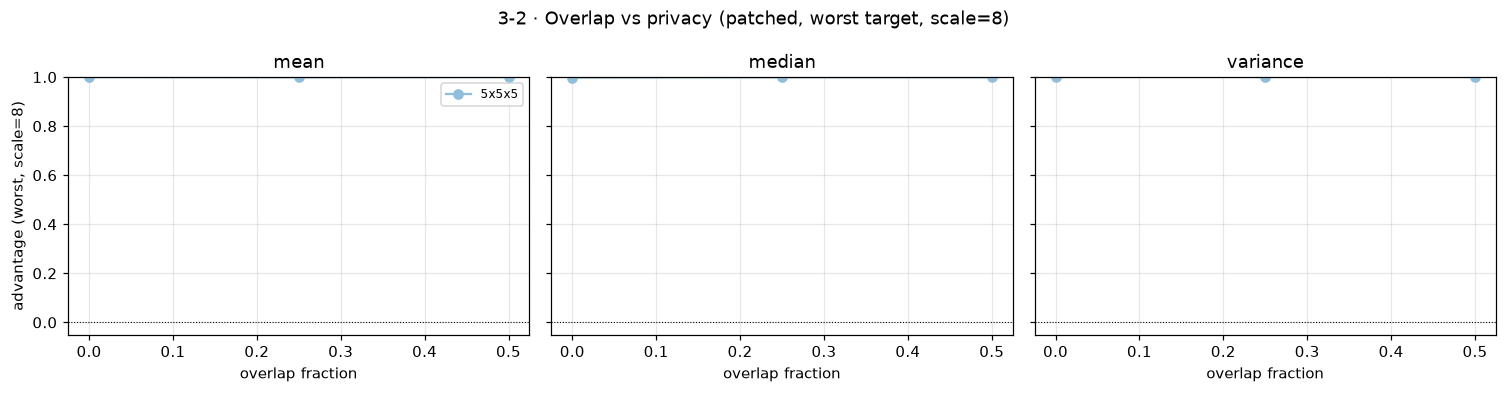

overlap effect (5x5x5, mean, worst) — advantage by scale x overlap:
overlap    0.0   0.25    0.5
scale                       
1        0.999  0.999  0.999
2        1.000  0.998  1.000
3        1.000  0.998  0.998
4        1.000  1.000  0.999
6        0.999  0.998  1.000
8        1.000  0.999  1.000
10       0.999  1.000  1.000
12       0.998  0.999  0.999
20       0.957  0.939  0.968
30       0.806  0.813  0.886
40       0.691  0.678  0.758
50       0.593  0.556  0.681
60       0.489  0.484  0.572
70       0.437  0.435  0.412
80       0.366  0.398  0.447
90       0.341  0.357  0.393
100      0.323  0.321  0.332


In [12]:
fig, axes = plt.subplots(1, len(STATS), figsize=(4.6*len(STATS), 3.6), squeeze=False, sharey=True)
for a, st in zip(axes[0], STATS):
    sub = RES[(RES.stat==st) & (RES.target=="worst") & (RES.scale==REP_SCALE) & (RES.patch!="single")]
    for nm in [p for p in PATCHES if p != "single"]:
        s = sub[sub.patch==nm].copy()
        if len(s):
            s["ov"] = s.overlap.astype(float); s = s.sort_values("ov")
            a.plot(s.ov, s.advantage, "o-", color=PCOL.get(nm), label=nm)
    a.set_title(st); a.set_xlabel("overlap fraction"); a.set_ylim(-0.05, 1.0)
    a.axhline(0.0, color="k", lw=.7, ls=":")
    if a is axes[0][0]: a.set_ylabel(f"advantage (worst, scale={REP_SCALE})"); a.legend(fontsize=8)
fig.suptitle(f"3-2 · Overlap vs privacy (patched, worst target, scale={REP_SCALE})")
plt.tight_layout(); plt.show()
print("overlap effect (5x5x5, mean, worst) — advantage by scale x overlap:")
print(RES[(RES.patch==REP_PATCH)&(RES.stat=="mean")&(RES.target=="worst")]
      .pivot_table(index="scale", columns="overlap", values="advantage").round(3).to_string())

## 3b · k_check (policing depth) → privacy and utility

Sweep the number of policed modes `k_check` ∈ {8, 16, 26, r} (r = full rank). Run on the
whole-brain **single** release (where advantage is in an informative range) **and** 5³ (saturated
reference), all targets, at a low and a high scale. Hypothesis: advantage **rises** as `k_check` falls
(tail modes left with only natural noise), at **lower** distortion — the test of whether full-rank
policing earns its cost. Both privacy and utility are measured vs `k_check`.

In [13]:
# single (informative) + a cheap saturated patched reference (7³). Builds run SEQUENTIALLY with the
# per-patch loop parallelised across cores (n_build_jobs) — far better core use than few uneven jobs.
KC_PATCHES = [("single","single"), (REF_PATCH, PATCHES[REF_PATCH])]
def _kc_job(pname, ps, st):
    ovv = 0.5; rel_full = R.build_release(COHORT, MASK, st, ps, ovv, BLEND, n_build_jobs=NB_BUILD)
    urows = []
    for sc in KC_SCALES:
        for kc in KCHECKS:
            u = R.release_utility(rel_full, sc, kc, np.random.default_rng(5), n_rel=N_REL)
            urows.append(dict(patch=pname, stat=st, scale=sc, k_check=("r" if kc is None else str(kc)),
                              rel_mse=u["rel_mse"], nc_gap=u["neighbour_corr_gap"],
                              spearman=u["spearman"], ssim=u["ssim"]))
    arows = []
    for target in TARGETS:
        gi, go, ri, ro, dv = R.two_worlds(COHORT, MASK, st, ps, ovv, BLEND, TGT[st][target],
                                          rel_full=(None if target=="ksigma" else rel_full), n_build_jobs=NB_BUILD)
        for sc in KC_SCALES:
            for rw in R.kcheck_sweep(gi, go, ri, ro, dv, sc, KCHECKS, N_TRIALS, np.random.default_rng(3)):
                arows.append(dict(patch=pname, stat=st, target=target, scale=sc,
                                  k_check=("r" if rw["k_check"] is None else str(rw["k_check"])),
                                  advantage=rw["advantage"]))
    return arows, urows
_arows, _urows = [], []
for pn, ps, st in [(pn, ps, st) for (pn, ps) in KC_PATCHES for st in STATS]:
    _t = time.time(); a, u = _kc_job(pn, ps, st); _arows += a; _urows += u
    print(f"  {pn}/{st} done in {time.time()-_t:.0f}s")
KC  = pd.DataFrame(_arows); KCU = pd.DataFrame(_urows)
kc_order = [("r" if k is None else str(k)) for k in KCHECKS]

  single/mean done in 78s
  single/median done in 127s
  single/variance done in 97s
  5x5x5/mean done in 2471s
  5x5x5/median done in 3509s
  5x5x5/variance done in 2951s


*Figure 3b-1 — privacy vs k_check.* At the **low** scale (where policing matters most),
**rows = patch** (single, 5³), **columns = statistic**; one line per target. x = k_check (8 → r).
5³ is expected flat-high (saturated); single is the informative row.

**What to expect, and why (this is a result, not a bug):** advantage is **largely flat in k_check** for
the single release. `k_noise = r`, so *every* mode always receives natural noise; `k_check` only toggles
the **bar floor** on policed modes, and that floor bites only where the bar exceeds the natural per-mode
noise `scale·√λₘ`. Since `bₘ = maxᵢ|Dᵢ·Vₘ| ≈ 2–4·√λₘ`, the floor adds little once scale lifts the
natural noise, and even at low scale it only nudges the parity modes. So **policing depth governs
worst-case coverage (§1b-B), not aggregate membership advantage — scale is the lever** (the bar-study
conclusion). Expect the mean to be flat and statistics whose Δ reaches the low-energy tail (e.g. median)
to show a *mild* decline toward k_check = r.

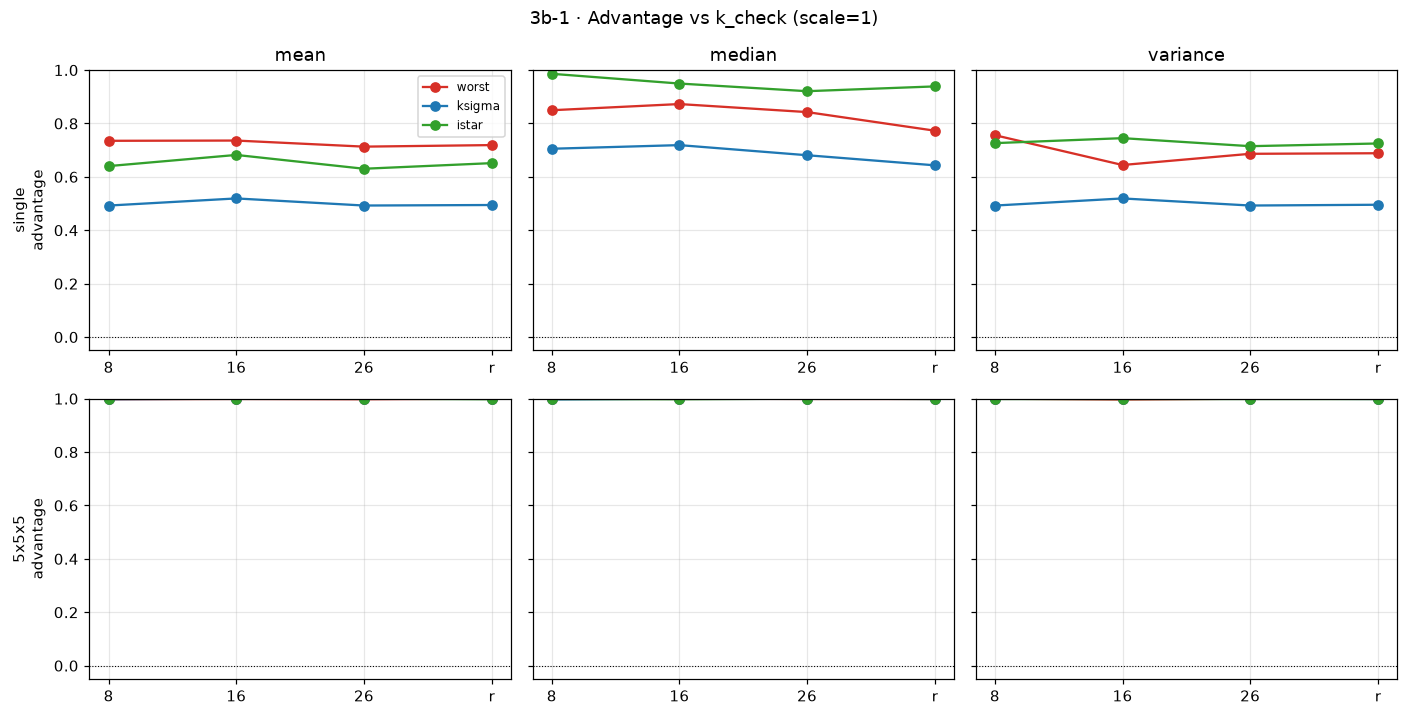

k_check                     8     16     26      r
patch  stat     target                            
5x5x5  mean     istar   1.000  1.000  1.000  0.998
                ksigma  0.998  1.000  1.000  1.000
                worst   0.998  0.999  0.998  1.000
       median   istar   0.999  0.998  1.000  0.999
                ksigma  0.997  1.000  1.000  0.999
                worst   1.000  1.000  0.999  0.999
       variance istar   1.000  1.000  1.000  1.000
                ksigma  1.000  1.000  1.000  0.999
                worst   1.000  0.997  1.000  1.000
single mean     istar   0.640  0.682  0.630  0.651
                ksigma  0.493  0.519  0.493  0.495
                worst   0.735  0.736  0.713  0.719
       median   istar   0.986  0.950  0.921  0.939
                ksigma  0.705  0.719  0.681  0.643
                worst   0.850  0.873  0.843  0.773
       variance istar   0.726  0.745  0.715  0.725
                ksigma  0.493  0.519  0.493  0.496
                worst   0.756  

In [14]:
LOW = KC_SCALES[0]
fig, axes = plt.subplots(len(KC_PATCHES), len(STATS), figsize=(4.3*len(STATS), 3.3*len(KC_PATCHES)),
                         squeeze=False, sharey=True)
for i,(pn,_) in enumerate(KC_PATCHES):
    for j, st in enumerate(STATS):
        a = axes[i][j]
        for tg in TARGETS:
            s = KC[(KC.patch==pn)&(KC.stat==st)&(KC.target==tg)&(KC.scale==LOW)].set_index("k_check")
            s = s.reindex([k for k in kc_order if k in s.index])
            a.plot(range(len(s)), s.advantage, "o-", color=TCOL[tg], label=tg)
        a.set_xticks(range(len(kc_order))); a.set_xticklabels(kc_order)
        a.set_ylim(-0.05,1.0); a.axhline(0,color="k",lw=.7,ls=":")
        if i==0: a.set_title(st)
        if j==0: a.set_ylabel(f"{pn}\nadvantage")
        if i==0 and j==0: a.legend(fontsize=8)
fig.suptitle(f"3b-1 · Advantage vs k_check (scale={LOW})"); plt.tight_layout(); plt.show()
print(KC[KC.scale==LOW].pivot_table(index=["patch","stat","target"], columns="k_check",
      values="advantage").reindex(columns=kc_order).round(3).to_string())

*Figure 3b-2 — utility vs k_check (statistic = mean, low scale).* All four utility metrics vs
k_check, one line per patch. **rel-MSE ↓ better; neighbour-corr gap ↓ better** (spatial smoothness
preserved); **Spearman ↑ better** (rank preserved); **SSIM ↑ better** (structural similarity). More
policed modes (toward r) cost at most marginally more distortion — read against 3b-1 to judge whether
the (small) privacy change is worth it.

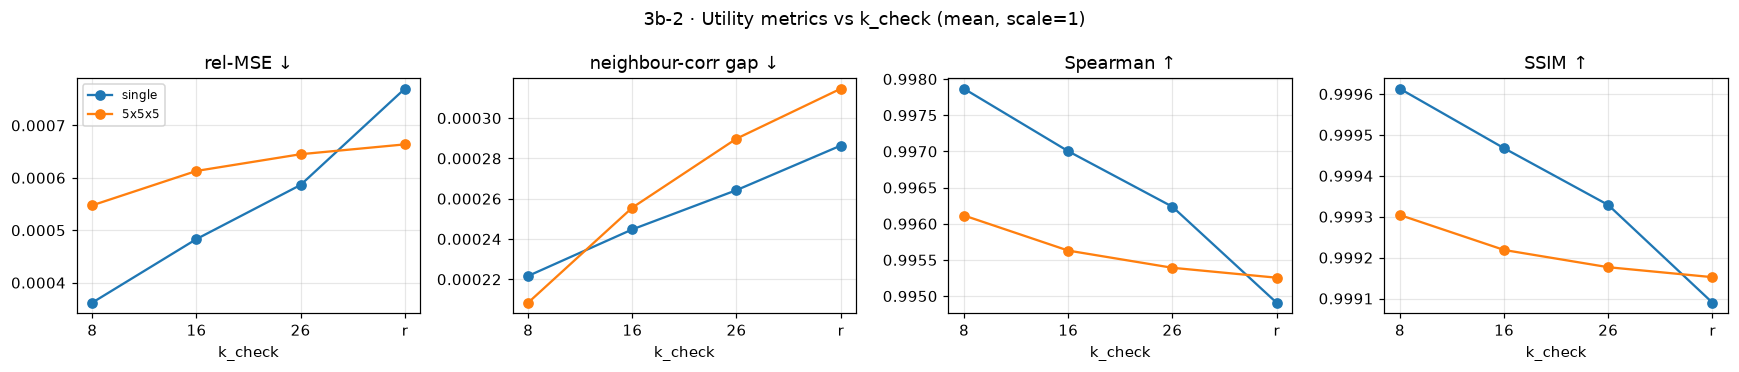

In [15]:
UMETRICS = [("rel_mse","rel-MSE ↓"), ("nc_gap","neighbour-corr gap ↓"),
            ("spearman","Spearman ↑"), ("ssim","SSIM ↑")]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4), squeeze=False)
for a, (col, lab) in zip(axes[0], UMETRICS):
    for pn, _ in KC_PATCHES:
        s = KCU[(KCU.patch==pn)&(KCU.stat=="mean")&(KCU.scale==LOW)].set_index("k_check")
        s = s.reindex([k for k in kc_order if k in s.index])
        a.plot(range(len(s)), s[col], "o-", label=pn)
    a.set_xticks(range(len(kc_order))); a.set_xticklabels(kc_order); a.set_title(lab); a.set_xlabel("k_check")
    if a is axes[0][0]: a.legend(fontsize=8)
fig.suptitle(f"3b-2 · Utility metrics vs k_check (mean, scale={LOW})"); plt.tight_layout(); plt.show()

## 3c · N-subject influence

*Figure 3c.* Membership **advantage (worst target) vs cohort size N**, at the operating scale, for
the whole-brain **single** release and 5³. x = N; one line per (patch, statistic). Prediction: roughly
flat with N (the bar scales with each subject's influence, so dilution cancels) — N buys privacy only
through rank/aggregation, which plateaus. Dotted line = chance.

[Parallel(n_jobs=20)]: Using backend LokyBackend with 20 concurrent workers.
[Parallel(n_jobs=20)]: Done   1 tasks      | elapsed:    7.7s
[Parallel(n_jobs=20)]: Done  10 tasks      | elapsed:   19.1s
[Parallel(n_jobs=20)]: Done  21 tasks      | elapsed:  1.2min
[Parallel(n_jobs=20)]: Done  32 tasks      | elapsed:  2.5min
/indirect/student/lukasschuler/DP_project/wp15/infrastructure/privacy_dev/privacy_env/lib64/python3.13/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
[Parallel(n_jobs=20)]: Done  45 tasks      | elapsed:  4.1min
[Parallel(n_jobs=20)]: Done  61 out of  90 | elapsed:  6.9min remaining:  3.3min
[Parallel(n_jobs=20)]: Done  71 out of  90 | elapsed:  9.7min remaining:  2.6min
[Parallel(n_jobs=20)]: Done  81 out of  90 | elapsed: 15.5min remaining:  1.7min
[Parallel(n_jobs=20)]: Done  90 out of  90 | 

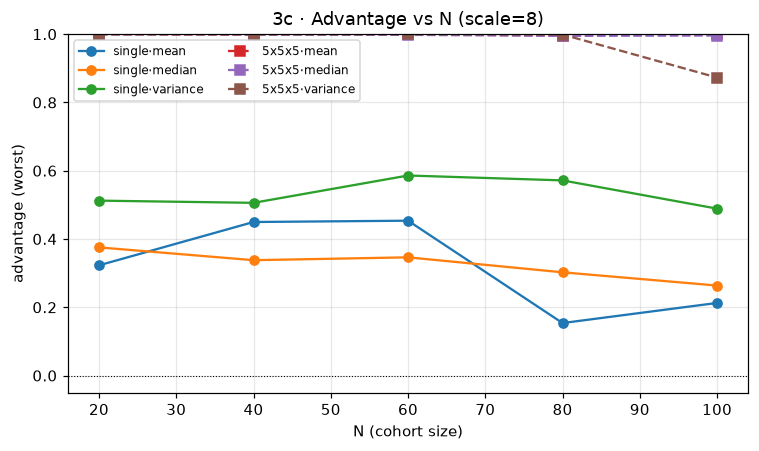

patch  5x5x5                 single                
stat    mean median variance   mean median variance
N                                                  
20     1.000  1.000    1.000  0.323  0.375    0.512
40     0.999  0.999    1.000  0.450  0.338    0.506
60     1.000  0.998    1.000  0.454  0.346    0.586
80     0.996  0.995    0.999  0.154  0.302    0.572
100    1.000  0.996    0.873  0.213  0.264    0.489


In [16]:
def _n_job(n, pname, ps, st, target):
    coh = VOLS[:n]; tgt = R.select_targets(coh, MASK, st)[target]
    gi, go, ri, ro, dv = R.two_worlds(coh, MASK, st, ps, 0.5, BLEND, tgt)
    adv = R.advantage_sweep(gi, go, ri, ro, dv, [REP_SCALE], None, N_TRIALS,
                            np.random.default_rng(4))[0]["advantage"]
    return dict(N=n, patch=pname, stat=st, target=target, advantage=adv)
_njobs = [(n, pn, ps, st, tg) for n in N_SWEEP for (pn, ps) in KC_PATCHES for st in STATS for tg in TARGETS]
NS = pd.DataFrame(Parallel(**PKW)(delayed(_n_job)(n, pn, ps, st, tg) for n, pn, ps, st, tg in _njobs))
fig, ax = plt.subplots(figsize=(7, 4.2))
for pn,_ in KC_PATCHES:
    for st in STATS:
        s = NS[(NS.patch==pn)&(NS.stat==st)&(NS.target=="worst")].sort_values("N")
        ax.plot(s.N, s.advantage, "o-" if pn=="single" else "s--", label=f"{pn}·{st}")
ax.set_xlabel("N (cohort size)"); ax.set_ylabel("advantage (worst)"); ax.set_ylim(-0.05, 1.0)
ax.axhline(0.0, color="k", lw=.7, ls=":"); ax.set_title(f"3c · Advantage vs N (scale={REP_SCALE})")
ax.legend(fontsize=8, ncol=2); plt.tight_layout(); plt.show()
print(NS[NS.target=="worst"].pivot_table(index="N", columns=["patch","stat"], values="advantage").round(3).to_string())

## 4 · Reconstruction + outlier-detectability (mean release)

**These are privacy / attack-success measures, not utility metrics.** This section asks a
different question from the rest: not "is the release useful?" (that is the utility panel — rel-MSE,
neighbour-corr gap, Spearman, SSIM — in §3/§6, and its dependence on scale is plotted in §6), but "can
an attacker reconstruct an individual from the release?".

For the identifiable **mean** release, an attacker who knows the N−1 background inverts the group mean
to recover the target voxel-wise: `x̂ = N·R − Σ(background) = target + N·z`, where `z` is the released
noise. We report two attack outcomes for **all three targets**:

- **Reconstruction error** `= ‖x̂ − target‖ / ‖target‖` — how far the attacker's recovered image is from
  the true subject, relative to the subject's size. **Higher = better privacy** (worse reconstruction).
  It rises with scale because the inversion multiplies the noise by N.
- **Outlier-flag rate** — how often the reconstruction trips a supervisor-style outlier test. Because of
  the ×N amplification it saturates at 1 (the attacker always flags *something*, but it is noise, not a
  confident identification), so it is shown only for transparency; the membership advantage (§3) is the
  sharper privacy measure.

*Figure 4.* **Left:** reconstruction error vs scale, one line per target (↑ = better protected).
**Right:** private outlier-flag rate vs scale (saturates at 1 due to the ×N amplification — shown for
transparency). Table beneath gives the raw numbers.

  target worst done
  target ksigma done
  target istar done


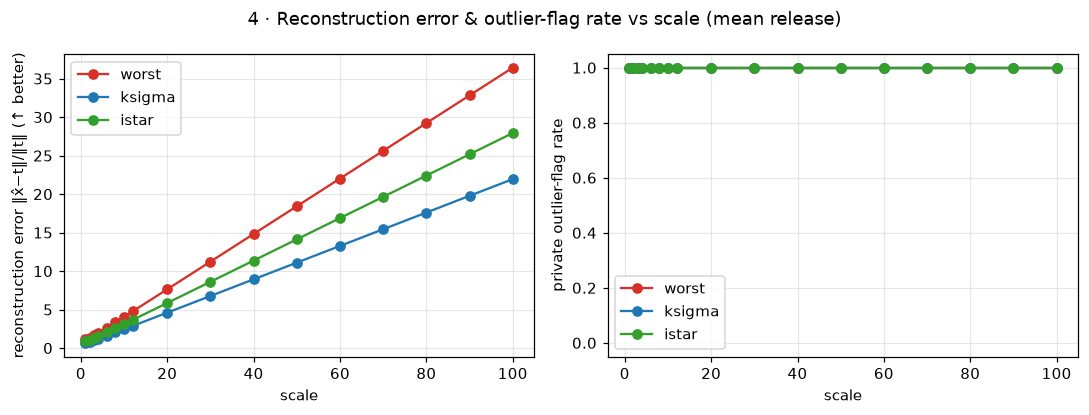

       private_z_rate              recon_err                
target          istar ksigma worst     istar  ksigma   worst
scale                                                       
1                 1.0    1.0   1.0     0.855   0.672   1.115
2                 1.0    1.0   1.0     1.043   0.820   1.361
3                 1.0    1.0   1.0     1.272   1.000   1.659
4                 1.0    1.0   1.0     1.520   1.194   1.982
6                 1.0    1.0   1.0     2.039   1.602   2.660
8                 1.0    1.0   1.0     2.574   2.022   3.356
10                1.0    1.0   1.0     3.115   2.447   4.062
12                1.0    1.0   1.0     3.659   2.875   4.772
20                1.0    1.0   1.0     5.853   4.599   7.633
30                1.0    1.0   1.0     8.607   6.763  11.225
40                1.0    1.0   1.0    11.366   8.930  14.822
50                1.0    1.0   1.0    14.126  11.098  18.421
60                1.0    1.0   1.0    16.886  13.267  22.021
70                1.0   

In [17]:
mb = MASK.reshape(-1); relS = R.build_release(COHORT, MASK, "mean", "single")
def _tgt_vox(tg):
    if tg == "ksigma": return TGT["mean"]["ksigma"].reshape(-1)[mb], COHORT.reshape(N,-1)[1:, mb]
    i = TGT["mean"][tg]; v = COHORT.reshape(N,-1)[:, mb]
    return v[i], np.delete(v, i, 0)
rows = []
for tg in TARGETS:
    tvox, bg = _tgt_vox(tg)
    for sc in SCALES:
        nmdl = R.fixed_noise(relS, sc, None)
        od = fra.outlier_detectability(bg, tvox, N, nmdl, np.random.default_rng(5), n_rel=min(200,4*N_REL))
        errs = [np.linalg.norm(tvox + N*nmdl.sample(np.random.default_rng(k)) - tvox)/(np.linalg.norm(tvox)+1e-12)
                for k in range(min(200,4*N_REL))]
        rows.append(dict(target=tg, scale=sc, clean_z_flag=od["clean_z_flag"],
                         private_z_rate=round(od["private_z_rate"],3), recon_err=round(float(np.mean(errs)),3)))
    print(f"  target {tg} done")
REC = pd.DataFrame(rows)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for tg in TARGETS:
    s = REC[REC.target==tg].sort_values("scale")
    ax[0].plot(s.scale, s.recon_err, "o-", color=TCOL[tg], label=tg)
    ax[1].plot(s.scale, s.private_z_rate, "o-", color=TCOL[tg], label=tg)
ax[0].set_xlabel("scale"); ax[0].set_ylabel("reconstruction error ‖x̂−t‖/‖t‖ (↑ better)"); ax[0].legend()
ax[1].set_xlabel("scale"); ax[1].set_ylabel("private outlier-flag rate"); ax[1].set_ylim(-0.05,1.05); ax[1].legend()
fig.suptitle("4 · Reconstruction error & outlier-flag rate vs scale (mean release)")
plt.tight_layout(); plt.show()
print(REC.pivot_table(index="scale", columns="target", values=["recon_err","private_z_rate"]).to_string())

## 5 · Inference validity on the imaging release (mass-univariate, corrected)

**What this section does, step by step.** We test whether publishing *mean map + mechanism noise*
breaks a standard downstream analysis — a per-voxel one-sample t-test across the cohort, corrected for
the ~p multiple comparisons. **Two separate simulations are run, because false-positive rate and power
are defined on different ground truths and cannot be measured on the same data** (a voxel either carries
a true effect or it does not — your supervisor's point):

1. **Null scenario → FWER / FDR (false positives).** We build a true null by **sign-flipping** each
   subject's centred deviation (a random ±1 per subject, applied to the whole brain). This preserves
   every voxel's variance but forces its true mean to 0, so *any* voxel called significant is a false
   positive. Over many sign-flip draws we measure the family-wise error rate (prob. of ≥1 false positive
   after **Bonferroni**) and the FDR false-positive rate (after **Benjamini–Hochberg**). With no noise
   this sits near α = 0.05; we then add the mechanism noise to the released mean map and re-run — the
   rise is the **Type-1 inflation** the privatisation causes.
2. **Signal scenario → power (true positives).** We inject a fixed effect into a known region (true mean
   0 elsewhere) and measure the fraction of truly-affected voxels detected (BH-corrected), clean vs
   privatised. This is **power**, meaningful only where a true effect exists.

FWER comes from simulation 1 and power from simulation 2 — never the same voxels — so the output keeps
them in separate blocks. Scale is swept over every integer 0–12 (0 = the clean, noise-free calibration).

*Figure 5.* Corrected **FWER (null scenario) vs scale**, one line per config (hard bar). Clean
(scale 0) should sit near α = 0.05 (dotted); the climb is the Type-1 inflation from the mechanism noise.

[Parallel(n_jobs=20)]: Using backend ThreadingBackend with 20 concurrent workers.
[Parallel(n_jobs=20)]: Done   5 out of  26 | elapsed:   33.6s remaining:  2.3min
[Parallel(n_jobs=20)]: Done  11 out of  26 | elapsed:   35.4s remaining:   48.3s
[Parallel(n_jobs=20)]: Done  17 out of  26 | elapsed:   37.0s remaining:   19.6s
[Parallel(n_jobs=20)]: Done  23 out of  26 | elapsed:  1.0min remaining:    8.1s
[Parallel(n_jobs=20)]: Done  26 out of  26 | elapsed:  1.1min finished


  inference single done


[Parallel(n_jobs=20)]: Using backend ThreadingBackend with 20 concurrent workers.
[Parallel(n_jobs=20)]: Done   5 out of  26 | elapsed: 107.5min remaining: 451.3min
[Parallel(n_jobs=20)]: Done  11 out of  26 | elapsed: 172.8min remaining: 235.7min
[Parallel(n_jobs=20)]: Done  17 out of  26 | elapsed: 594.9min remaining: 314.9min
[Parallel(n_jobs=20)]: Done  23 out of  26 | elapsed: 599.3min remaining: 78.2min
[Parallel(n_jobs=20)]: Done  26 out of  26 | elapsed: 615.7min finished


  inference 5x5x5 done
NULL scenario (sign-flip, true mean 0) -> false positives [hard bar]  (FWER=Bonferroni, BHfp=FDR):
config  scale  FWER_clean  FWER_priv  BHfp_priv
 5x5x5    0.0       0.055      0.055      0.055
 5x5x5    1.0       0.055      0.215      0.245
 5x5x5    2.0       0.055      0.360      0.400
 5x5x5    3.0       0.055      0.610      0.690
 5x5x5    4.0       0.055      0.860      0.970
 5x5x5    5.0       0.055      0.985      0.995
 5x5x5    6.0       0.055      1.000      1.000
 5x5x5    7.0       0.055      1.000      1.000
 5x5x5    8.0       0.055      1.000      1.000
 5x5x5    9.0       0.055      1.000      1.000
 5x5x5   10.0       0.055      1.000      1.000
 5x5x5   11.0       0.055      1.000      1.000
 5x5x5   12.0       0.055      1.000      1.000
single    0.0       0.055      0.055      0.055
single    1.0       0.055      0.210      0.235
single    2.0       0.055      0.285      0.350
single    3.0       0.055      0.415      0.495
single    4.0 

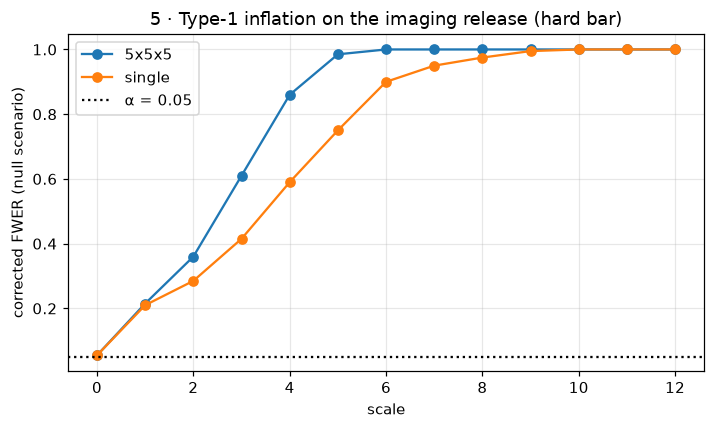

In [18]:
# build each mean release ONCE per config (release is scale/mechanism-independent), then run both
# mechanisms over all scales with THREADED parallelism — shares the release (no pickling, no rebuilds).
inf_cfgs = [("single", "single", None)] + ([("5x5x5", (5,5,5), 0.5)] if "5x5x5" in PATCHES else [])
INF_MODES = ["hardbar", "optB"]
_both = []
for nm, ps, ov in inf_cfgs:
    relm = R.build_release(COHORT, MASK, "mean", ps, (0.5 if ov is None else ov), BLEND, n_build_jobs=NB_BUILD)
    def _one(sc, mode, relm=relm, nm=nm):
        o = R.imaging_inference(relm, COHORT, MASK, float(sc), None, alpha=0.05, n_mc=N_MC, effect=0.8,
                                region_frac=0.05, seed=SEED, mode=mode)
        return dict(config=nm, mech=mode, scale=float(sc), FWER_clean=round(o["fwer_clean"],3),
                    FWER_priv=round(o["fwer_priv"],3), BHfp_priv=round(o["fdr_fp_priv"],3),
                    pow_clean=round(o["pow_bh_clean"],3), pow_priv=round(o["pow_bh_priv"],3))
    _both += Parallel(n_jobs=min(len(INF_SCALES)*len(INF_MODES), N_JOBS), prefer="threads", verbose=5)(
        delayed(_one)(sc, mode) for sc in INF_SCALES for mode in INF_MODES)
    print(f"  inference {nm} done")
BOTH = pd.DataFrame(_both).sort_values(["config","mech","scale"])
INF = BOTH[BOTH.mech=="hardbar"]
print("NULL scenario (sign-flip, true mean 0) -> false positives [hard bar]  (FWER=Bonferroni, BHfp=FDR):")
print(INF[["config","scale","FWER_clean","FWER_priv","BHfp_priv"]].to_string(index=False))
print("\nSIGNAL scenario (injected effect) -> power [hard bar]  (BH-corrected detected fraction):")
print(INF[["config","scale","pow_clean","pow_priv"]].to_string(index=False))
fig, ax = plt.subplots(figsize=(6.6, 4))
for nm in INF.config.unique():
    s = INF[INF.config==nm].sort_values("scale"); ax.plot(s.scale, s.FWER_priv, "o-", label=f"{nm}")
ax.axhline(0.05, color="k", ls=":", label="α = 0.05"); ax.set_xlabel("scale"); ax.set_ylabel("corrected FWER (null scenario)")
ax.set_title("5 · Type-1 inflation on the imaging release (hard bar)"); ax.legend(); plt.tight_layout(); plt.show()

### 5b · Option B (variance-inflation) — the inference-friendlier alternative

**Option B restated:** instead of forcing `|aₘ| ≥ bₘ` every draw (the hard bar, non-Gaussian), each
mode is plain Gaussian `aₘ ~ N(0, σₘ²)` with `σₘ² = max(scale²·λₘ, bₘ²)` — it covers the bar *in
expectation*, not per draw, so the noise stays Gaussian. Hypothesis: Option B keeps Type-1 near nominal
while the hard bar inflates it. Below: the **same** inference experiment, same configs/scales, hard bar
vs Option B, so the effect is directly comparable.

*Figure 5b.* Corrected FWER (null) vs scale; **solid = hard bar, dashed = Option B**, one colour
per config. Option B staying near α while hard bar climbs would confirm the inference advantage of the
Gaussian variant.

hard bar vs Option B, matched conditions  (FWER_priv = NULL-scenario false positives; pow_priv = SIGNAL-scenario power):
             FWER_priv        pow_priv       
mech           hardbar   optB  hardbar   optB
config scale                                 
5x5x5  0.0       0.055  0.090    0.981  0.969
       1.0       0.215  0.090    0.966  0.969
       2.0       0.360  0.090    0.958  0.969
       3.0       0.610  0.170    0.948  0.965
       4.0       0.860  0.415    0.938  0.954
       5.0       0.985  0.795    0.928  0.942
       6.0       1.000  0.975    0.920  0.931
       7.0       1.000  1.000    0.912  0.921
       8.0       1.000  1.000    0.904  0.913
       9.0       1.000  1.000    0.895  0.904
       10.0      1.000  1.000    0.885  0.895
       11.0      1.000  1.000    0.875  0.886
       12.0      1.000  1.000    0.865  0.876
single 0.0       0.055  0.115    0.980  0.965
       1.0       0.210  0.115    0.960  0.965
       2.0       0.285  0.115    0.953  0.965
     

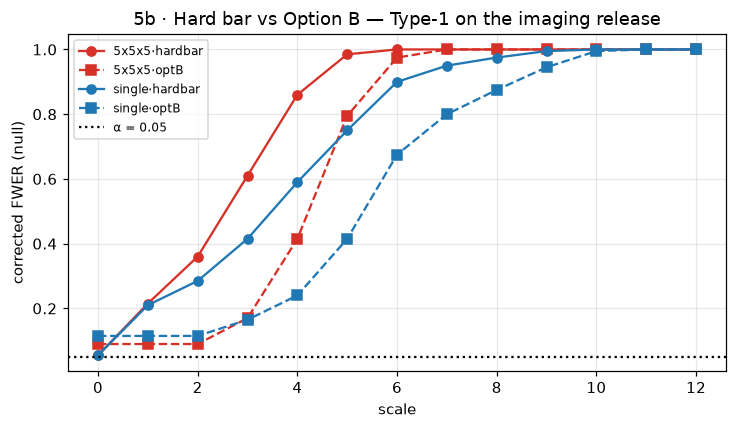

In [19]:
INFB = BOTH[BOTH.mech=="optB"]           # computed together with the hard bar in §5 (no rebuild)
print("hard bar vs Option B, matched conditions  (FWER_priv = NULL-scenario false positives; "
      "pow_priv = SIGNAL-scenario power):")
print(BOTH.pivot_table(index=["config","scale"], columns="mech",
      values=["FWER_priv","pow_priv"]).round(3).to_string())
fig, ax = plt.subplots(figsize=(6.8, 4)); ccol = {c:col for c,col in zip(INF.config.unique(), ["#d73027","#1f78b4"])}
for nm in BOTH.config.unique():
    for mech, ls in [("hardbar","o-"), ("optB","s--")]:
        s = BOTH[(BOTH.config==nm)&(BOTH.mech==mech)].sort_values("scale")
        ax.plot(s.scale, s.FWER_priv, ls, color=ccol.get(nm,"k"), label=f"{nm}·{mech}")
ax.axhline(0.05, color="k", ls=":", label="α = 0.05"); ax.set_xlabel("scale"); ax.set_ylabel("corrected FWER (null)")
ax.set_title("5b · Hard bar vs Option B — Type-1 on the imaging release"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 6 · Frontier, utility panel, and configuration selection

*Figure 6.* Privacy–utility frontier: **advantage (x, ↓ better) vs rel-MSE (y, log, ↓ better)**,
one marker per scale connected per patch; **rows = targets**, **columns = statistics**; lower-left is
better. Single in red.

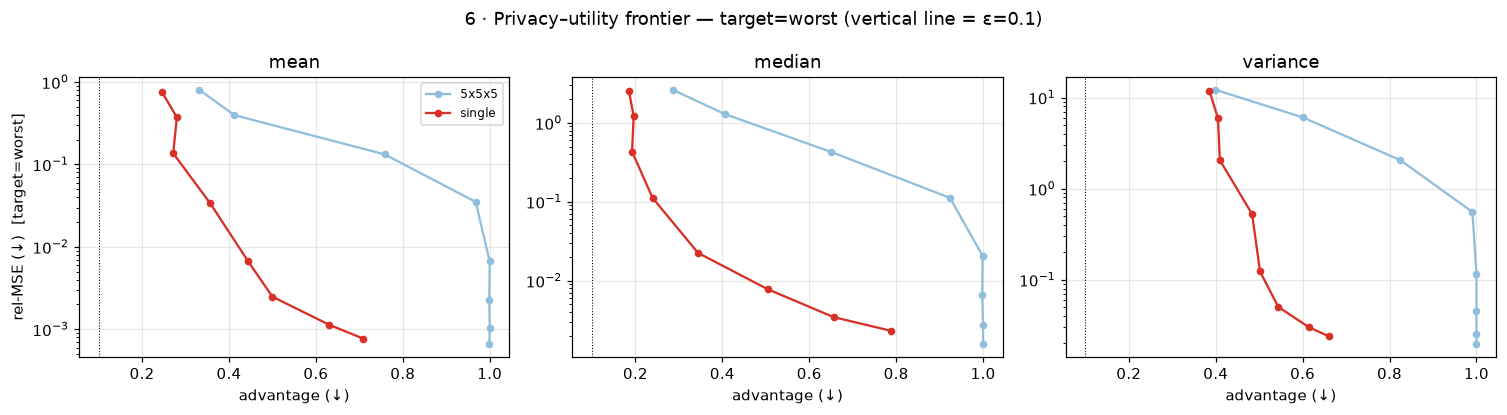

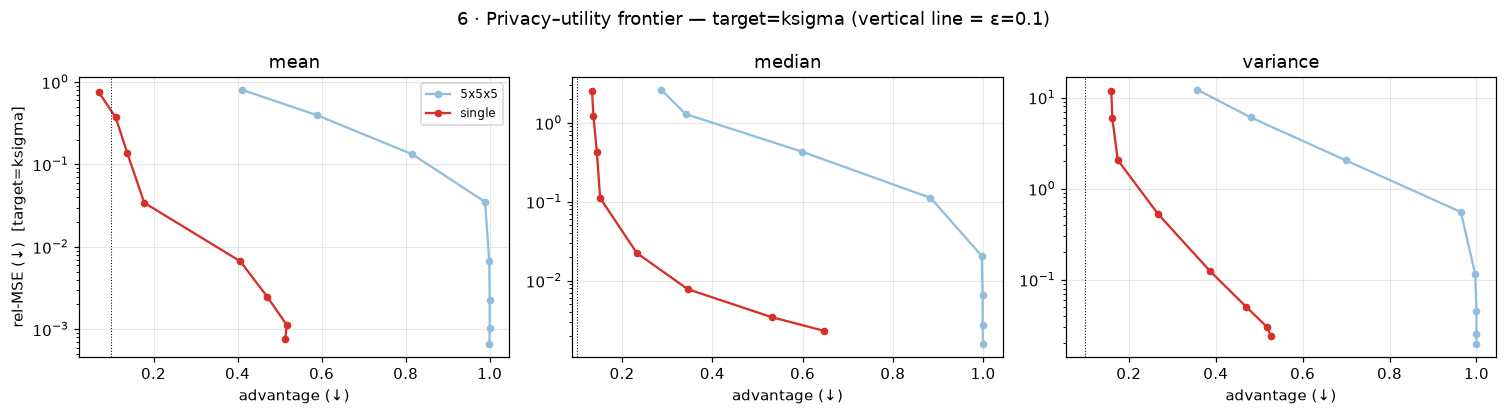

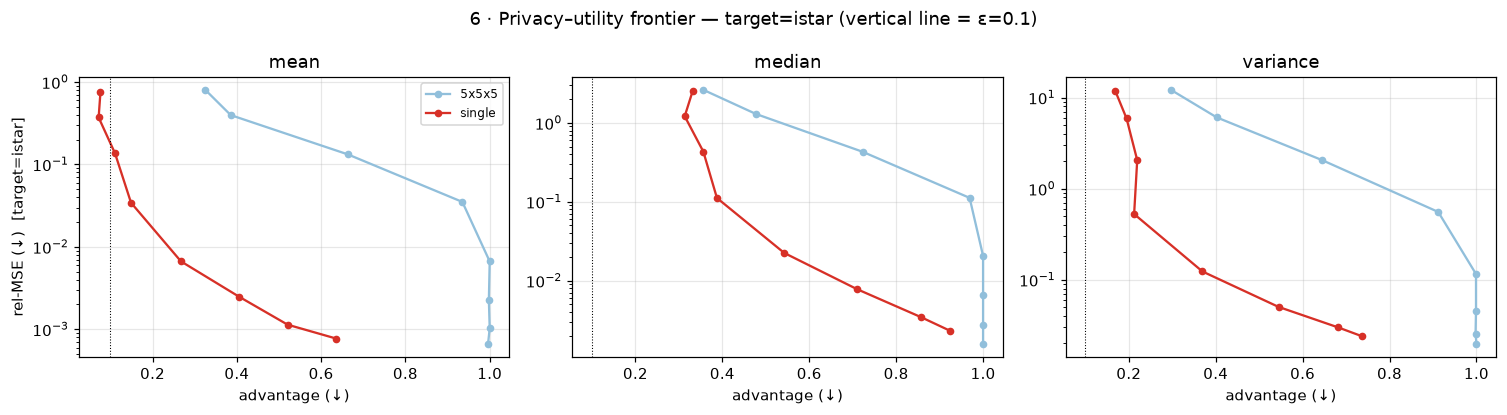

In [20]:
for TG in TGTS_RES:
    fig, axes = plt.subplots(1, len(STATS), figsize=(4.6*len(STATS), 3.8), squeeze=False)
    for a, st in zip(axes[0], STATS):
        sub = _ov05(RES[(RES.stat==st) & (RES.target==TG)])
        for nm in PATCHES:
            s = sub[sub.patch==nm].dropna(subset=["rel_mse"]).sort_values("scale")   # utility only at UTIL_SCALES
            if len(s): a.plot(s.advantage, s.rel_mse, "o-", color=PCOL.get(nm), label=nm, ms=4)
        a.set_title(st); a.set_xlabel("advantage (↓)"); a.set_yscale("log"); a.axvline(EPS,color="k",lw=.7,ls=":")
        if a is axes[0][0]: a.set_ylabel(f"rel-MSE (↓)  [target={TG}]"); a.legend(fontsize=8)
    fig.suptitle(f"6 · Privacy–utility frontier — target={TG} (vertical line = ε={EPS})")
    plt.tight_layout(); plt.show()

*Figure 6b — all utility metrics vs scale* (statistic = mean, overlap 0.5, single vs 5³). Each
panel is one metric: **rel-MSE ↓ better**, **neighbour-corr gap ↓ better** (spatial smoothness
preserved), **Spearman ↑ better** (rank preserved), **SSIM ↑ better** (structural similarity; NaN
without scikit-image). Utility degrades as scale rises — this is the cost side of the frontier, so read
it against the advantage-vs-scale curves (§3-1) at the same scales.

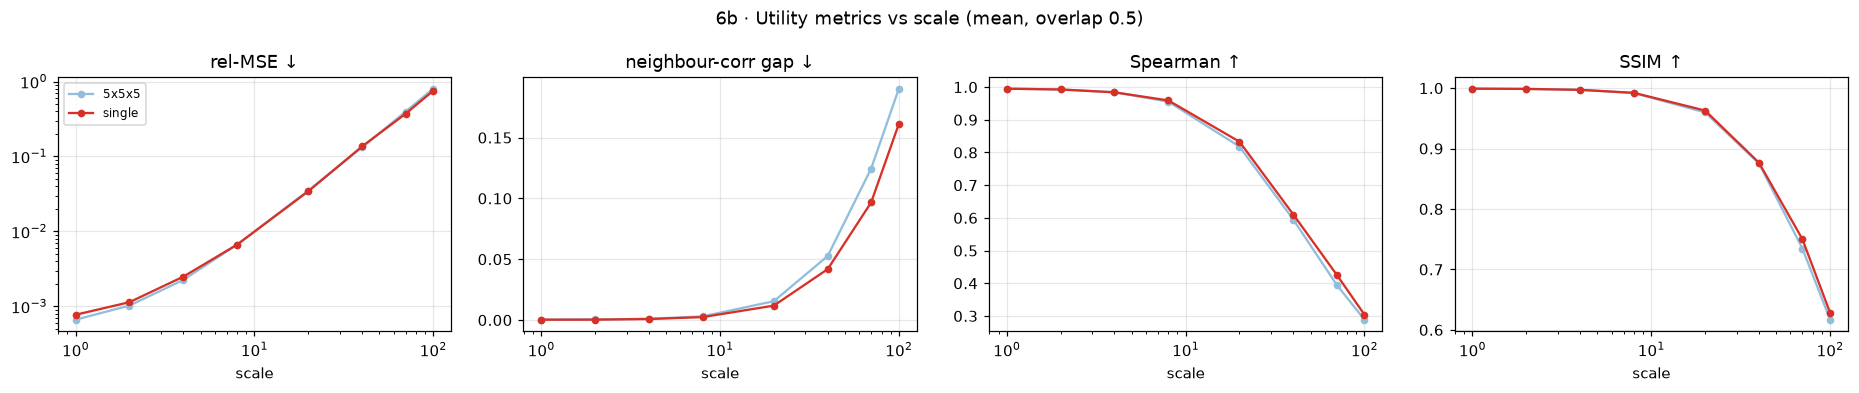

utility panel @ scale=8, mean:   (rel_mse↓ nc_gap↓ spearman↑ ssim↑)
 patch overlap  n_patches  rel_mse  nc_gap  spearman   ssim
single       -          1   0.0067  0.0024    0.9591 0.9922
 5x5x5     0.5      17560   0.0066  0.0030    0.9555 0.9917


In [21]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6), squeeze=False)
for a, (col, lab) in zip(axes[0], [("rel_mse","rel-MSE ↓"), ("nc_gap","neighbour-corr gap ↓"),
                                   ("spearman","Spearman ↑"), ("ssim","SSIM ↑")]):
    for nm in PATCHES:
        s = _ov05(RES[(RES.stat=="mean") & (RES.target=="worst") & (RES.patch==nm)]).dropna(subset=[col]).sort_values("scale")
        if len(s): a.plot(s.scale, s[col], "o-", color=PCOL.get(nm), label=nm, ms=4)
    a.set_title(lab); a.set_xlabel("scale"); a.set_xscale("log")
    if col == "rel_mse": a.set_yscale("log")
    if a is axes[0][0]: a.legend(fontsize=8)
fig.suptitle("6b · Utility metrics vs scale (mean, overlap 0.5)"); plt.tight_layout(); plt.show()
pan = _ov05(RES[(RES.stat=="mean") & (RES.target=="worst") & (RES.scale==REP_SCALE)])
cols = ["patch","overlap","n_patches","rel_mse","nc_gap","spearman","ssim"]
print(f"utility panel @ scale={REP_SCALE}, mean:   (rel_mse↓ nc_gap↓ spearman↑ ssim↑)")
print(pan[cols].sort_values("n_patches").round(4).to_string(index=False))

### Configuration selection

**Objective:** minimise membership advantage subject to utility, at least computational cost.
**Criterion:** a config is *acceptable* when the **upper 95 % CI of advantage ≤ ε = 0.1** for the worst
target at some tested scale. **Cost** proxy: number of patch builds (`n_patches`).

In [22]:
print(f"smallest scale with adv_hi <= {EPS} (worst target), per config (overlap 0.5 / single):")
sel = _ov05(RES[RES.target=="worst"])
recs = []
for (nm, st), g in sel.groupby(["patch","stat"]):
    ok = g[g.adv_hi <= EPS].sort_values("scale")
    npat = int(g.n_patches.iloc[0])
    if len(ok):
        b = ok.iloc[0]; recs.append(dict(patch=nm, stat=st, meets=True, scale=int(b.scale),
                                         adv_hi=round(b.adv_hi,3), rel_mse=round(b.rel_mse,4), n_patches=npat))
    else:
        b = g.sort_values("scale").iloc[-1]
        recs.append(dict(patch=nm, stat=st, meets=False, scale=f">{int(b.scale)}",
                         adv_hi=round(b.adv_hi,3), rel_mse=round(b.rel_mse,4), n_patches=npat))
SELE = pd.DataFrame(recs).sort_values(["stat","n_patches"])
print(SELE.to_string(index=False))
meets = SELE[SELE.meets]
if len(meets):
    cheap = meets.sort_values(["stat","n_patches"]).groupby("stat").first()
    print("\nconfigs meeting the criterion, cheapest per statistic:"); print(cheap.to_string())
else:
    print(f"\nNO tested config reaches adv_hi <= {EPS} within scale {max(SCALES)}. "
          f"Cheapest + most private is `single` (n_patches=1); it needs scale beyond the tested range "
          f"for mean/variance. Recommendation: `single` + a higher scale; see the frontier for the trade-off.")

smallest scale with adv_hi <= 0.1 (worst target), per config (overlap 0.5 / single):
 patch     stat  meets scale  adv_hi  rel_mse  n_patches
single     mean  False  >100   0.280   0.7541          1
 5x5x5     mean  False  >100   0.375   0.8041      17560
single   median  False  >100   0.220   2.5181          1
 5x5x5   median  False  >100   0.329   2.6268      17560
single variance  False  >100   0.419  11.9409          1
 5x5x5 variance  False  >100   0.432  12.1766      17560

NO tested config reaches adv_hi <= 0.1 within scale 100. Cheapest + most private is `single` (n_patches=1); it needs scale beyond the tested range for mean/variance. Recommendation: `single` + a higher scale; see the frontier for the trade-off.


## 9 · Isolated-patch baselines (leakage before assembly)

Does a **single isolated patch** release leak before any tiling/blending? Release ONE patch of
size {3³,5³,7³} centred on the worst target's peak-|Δ| voxel, with no assembly, and run the same
projection attack. Compare to (i) the **assembled** tiled release of the same patch size (from §3,
overlap 0.5) and (ii) the whole-brain **single** release. This separates per-patch leakage from any
amplification introduced by overlap/blending.

*Figure 9.* Membership **advantage (worst, mean) vs scale**. **Solid** = isolated single patch;
**dashed** = assembled tiled release of the same size (from §3); red = whole-brain single. If isolated
patches already leak, privacy loss is intrinsic to the patch statistic, not to assembly.

[Parallel(n_jobs=20)]: Using backend LokyBackend with 20 concurrent workers.
[Parallel(n_jobs=20)]: Done   1 tasks      | elapsed:    3.2s


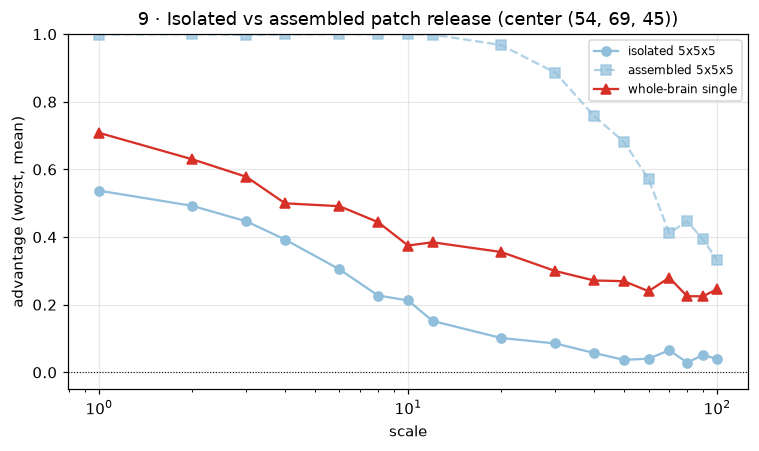

size   5x5x5
scale       
1      0.537
2      0.492
3      0.446
4      0.393
6      0.305
8      0.227
10     0.213
12     0.152
20     0.102
30     0.085
40     0.057
50     0.037
60     0.040
70     0.065
80     0.029
90     0.051
100    0.040


In [23]:
st = "mean"; tgt = TGT[st]["worst"]
center = tuple(int(c) for c in R.peak_influence_voxel(COHORT, MASK, st, tgt))
iso_rows = []
def _iso_job(psz):
    gi, go, ri, ro, dv, npx = R.isolated_patch_worlds(COHORT, MASK, st, psz, center, tgt)
    out = []
    for rw in R.advantage_sweep(gi, go, ri, ro, dv, SCALES, None, N_TRIALS, np.random.default_rng(9)):
        out.append(dict(size=f"{psz[0]}x{psz[1]}x{psz[2]}", npx=npx, scale=rw["scale"], advantage=rw["advantage"]))
    return out
ISO = pd.DataFrame([r for rows in Parallel(**PKW)(delayed(_iso_job)(p) for p in ISO_SIZES) for r in rows])
fig, ax = plt.subplots(figsize=(7, 4.2))
for psz in ISO_SIZES:
    key = f"{psz[0]}x{psz[1]}x{psz[2]}"; s = ISO[ISO["size"]==key].sort_values("scale")
    ax.plot(s.scale, s.advantage, "o-", color=PCOL.get(key), label=f"isolated {key}")
    asm = _ov05(RES[(RES.stat==st)&(RES.target=="worst")&(RES.patch==key)]).sort_values("scale")
    if len(asm): ax.plot(asm.scale, asm.advantage, "s--", color=PCOL.get(key), alpha=.7, label=f"assembled {key}")
sgl = RES[(RES.stat==st)&(RES.target=="worst")&(RES.patch=="single")].sort_values("scale")
if len(sgl): ax.plot(sgl.scale, sgl.advantage, "^-", color=PCOL["single"], label="whole-brain single")
ax.set_xscale("log"); ax.set_xlabel("scale"); ax.set_ylabel("advantage (worst, mean)"); ax.set_ylim(-0.05,1.0)
ax.axhline(0,color="k",lw=.7,ls=":"); ax.set_title(f"9 · Isolated vs assembled patch release (center {center})")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()
print(ISO.pivot_table(index="scale", columns="size", values="advantage").round(3).to_string())

## 10 · Blend comparison (average vs pou vs pou_energy)

Does *how* we blend overlapping patches change privacy? At 5³ / overlap 0.5, all targets, sweep
scale and compare the three blends. **Hypothesis:** plain `average` sums independent patch-noises and
averages them *down* (less noise along a coherent attack → more leak); `pou_energy` divides by √Σw²,
preserving noise energy (least leak); `pou` sits between. This isolates how much of the patched leak is
the blend throwing noise away.

*Figure 10.* **Left:** advantage (worst target) vs scale, one line per blend (lower = more
private). **Right:** utility rel-MSE vs scale per blend (lower = better). Columns would be statistics;
shown for mean. Dotted line = chance.

  blend average done
  blend pou done
  blend pou_energy done


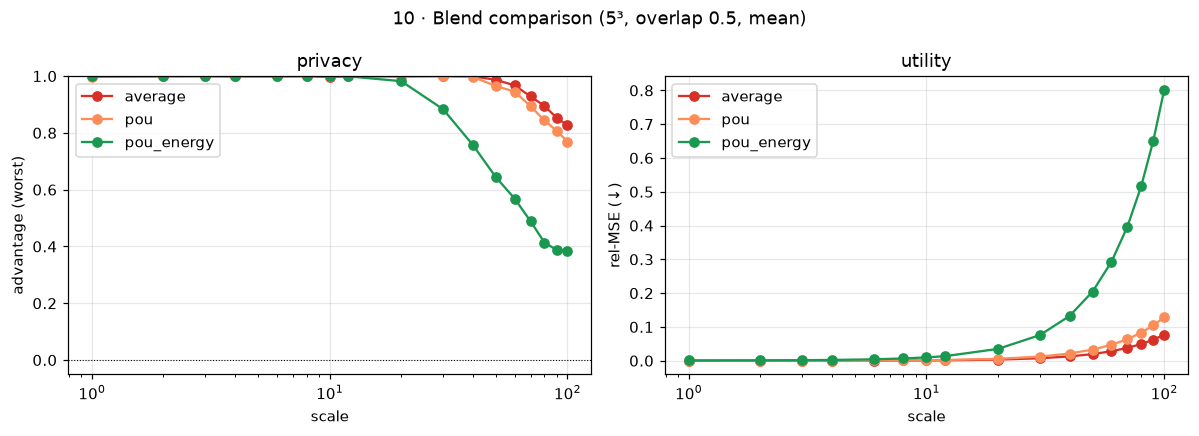

blend  average    pou  pou_energy
scale                            
1        0.999  0.998       0.999
2        1.000  0.999       1.000
3        1.000  1.000       1.000
4        1.000  1.000       0.999
6        0.999  1.000       1.000
8        1.000  1.000       1.000
10       0.997  0.999       0.999
12       0.999  0.999       0.999
20       0.999  0.999       0.982
30       1.000  1.000       0.883
40       0.999  0.997       0.757
50       0.987  0.965       0.644
60       0.967  0.945       0.568
70       0.928  0.893       0.488
80       0.895  0.844       0.414
90       0.853  0.807       0.388
100      0.826  0.769       0.384


In [24]:
BA_rows = []
for bl in BLENDS:
    rel_full = R.build_release(COHORT, MASK, "mean", (5,5,5), 0.5, bl, n_build_jobs=NB_BUILD)
    for tg in TARGETS:
        gi, go, ri, ro, dv = R.two_worlds(COHORT, MASK, "mean", (5,5,5), 0.5, bl, TGT["mean"][tg],
                                          rel_full=(None if tg=="ksigma" else rel_full), n_build_jobs=NB_BUILD)
        for rw in R.advantage_sweep(gi, go, ri, ro, dv, SCALES, None, N_TRIALS, np.random.default_rng(10)):
            BA_rows.append(dict(blend=bl, target=tg, scale=rw["scale"], advantage=rw["advantage"]))
    for sc in SCALES:
        u = R.release_utility(rel_full, sc, None, np.random.default_rng(11), n_rel=N_REL)
        BA_rows.append(dict(blend=bl, target="_util", scale=sc, rel_mse=u["rel_mse"]))
    print(f"  blend {bl} done")
BA = pd.DataFrame(BA_rows)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
bcol = {"average":"#d73027","pou":"#fc8d59","pou_energy":"#1a9850"}
for bl in BLENDS:
    s = BA[(BA.blend==bl)&(BA.target=="worst")].sort_values("scale")
    ax[0].plot(s.scale, s.advantage, "o-", color=bcol[bl], label=bl)
    u = BA[(BA.blend==bl)&(BA.target=="_util")].sort_values("scale")
    ax[1].plot(u.scale, u.rel_mse, "o-", color=bcol[bl], label=bl)
ax[0].set_xscale("log"); ax[0].set_xlabel("scale"); ax[0].set_ylabel("advantage (worst)"); ax[0].set_ylim(-0.05,1.0)
ax[0].axhline(0,color="k",lw=.7,ls=":"); ax[0].legend(); ax[0].set_title("privacy")
ax[1].set_xscale("log"); ax[1].set_xlabel("scale"); ax[1].set_ylabel("rel-MSE (↓)"); ax[1].legend(); ax[1].set_title("utility")
fig.suptitle("10 · Blend comparison (5³, overlap 0.5, mean)"); plt.tight_layout(); plt.show()
print(BA[BA.target=="worst"].pivot_table(index="scale", columns="blend", values="advantage").round(3).to_string())

## 11 · Number of patches → privacy (the aggregation test)

Place exactly k patches (5³) centred on the worst target's peak influence, release **only that
region**, and attack it. If the leak is driven by aggregating independent patches, advantage should
**rise with k** (roughly like √k until it saturates). Two placements: **non-overlapping** (stride =
patch size → k genuinely independent pieces) and **50 % overlapping** (stride = patch/2 → denser
packing, smaller region). Comparing them separates patch *count* from region *size*.

*Figure 11.* Advantage (worst, mean) vs number of patches k (log2 x), at a low and the operating
scale; **solid = non-overlapping, dashed = overlapping**. A rising curve confirms the aggregation
mechanism. (Caveat: as k grows the released region also grows, more so for non-overlapping — the
overlapping curve isolates adding patches into a smaller region.)

  k=1 non-overlap done in 0s
  k=2 non-overlap done in 0s
  k=4 non-overlap done in 1s
  k=8 non-overlap done in 1s
  k=16 non-overlap done in 1s
  k=32 non-overlap done in 1s
  k=64 non-overlap done in 2s
  k=1 overlap done in 1s
  k=2 overlap done in 1s
  k=4 overlap done in 1s
  k=8 overlap done in 1s
  k=16 overlap done in 1s
  k=32 overlap done in 2s
  k=64 overlap done in 3s


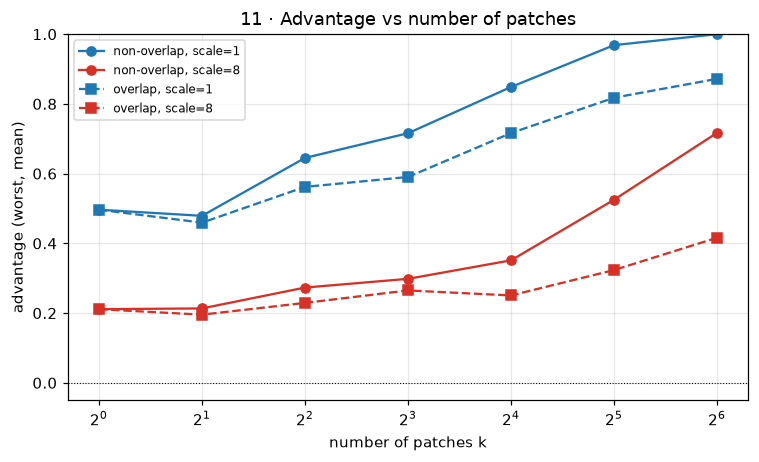

placement non-overlap        overlap       
scale               1      8       1      8
k                                          
1               0.496  0.211   0.496  0.211
2               0.479  0.213   0.459  0.195
4               0.645  0.273   0.562  0.229
8               0.716  0.298   0.590  0.265
16              0.849  0.351   0.716  0.251
32              0.969  0.525   0.818  0.323
64              1.000  0.717   0.872  0.416


In [25]:
st = "mean"; tgt = TGT[st]["worst"]; center = R.peak_influence_voxel(COHORT, MASK, st, tgt)
EXPB_SCALES = [KC_SCALES[0], REP_SCALE]
def _expb(k, placement, sc_list):
    stride = EXPB_SIZE if placement=="non-overlap" else tuple(max(1, s//2) for s in EXPB_SIZE)
    origins = R.grid_origins(center, EXPB_SIZE, stride, k, MASK.shape, MASK)
    gi, go, ri, ro, dv, nvox = R.two_worlds_boxes(COHORT, MASK, st, origins, EXPB_SIZE, BLEND, tgt,
                                                  n_build_jobs=NB_BUILD)
    rows = []
    for rw in R.advantage_sweep(gi, go, ri, ro, dv, sc_list, None, N_TRIALS, np.random.default_rng(12)):
        rows.append(dict(k=len(origins), placement=placement, scale=rw["scale"],
                         advantage=rw["advantage"], region_vox=nvox))
    return rows
EB = []
for placement in ["non-overlap", "overlap"]:
    for k in EXPB_K:
        _t=time.time(); EB += _expb(k, placement, EXPB_SCALES); print(f"  k={k} {placement} done in {time.time()-_t:.0f}s")
EB = pd.DataFrame(EB)
fig, ax = plt.subplots(figsize=(7, 4.3))
for placement, ls in [("non-overlap","o-"), ("overlap","s--")]:
    for sc, col in zip(EXPB_SCALES, ["#1f78b4","#d73027"]):
        s = EB[(EB.placement==placement)&(EB.scale==sc)].sort_values("k")
        ax.plot(s.k, s.advantage, ls, color=col, label=f"{placement}, scale={sc}")
ax.set_xscale("log", base=2); ax.set_xlabel("number of patches k"); ax.set_ylabel("advantage (worst, mean)")
ax.set_ylim(-0.05,1.0); ax.axhline(0,color="k",lw=.7,ls=":"); ax.set_title("11 · Advantage vs number of patches")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()
print(EB.pivot_table(index="k", columns=["placement","scale"], values="advantage").round(3).to_string())

## 12 · Δ-energy coverage (how much of the attack direction the noise can reach)

The scale-proof part of the leak: if the attack direction Δ has a component in a subspace the
mechanism never noises, that component leaks at *any* scale. We measure `coverage = ‖P_noise Δ‖² /
‖Δ‖²` — the fraction of Δ's energy inside the noise span. Crucially for the **out-world** release, whose
modes are built *without* the target, so Δ (the target's own direction) can fall partly in the null
space.

*Figure 12.* Coverage fraction (1.0 = fully maskable) per configuration, **in-world vs out-world**,
one panel per statistic. A bar below 1.0 in the out-world is energy no scale can hide. (worst target.)

  coverage mean done
  coverage median done
  coverage variance done


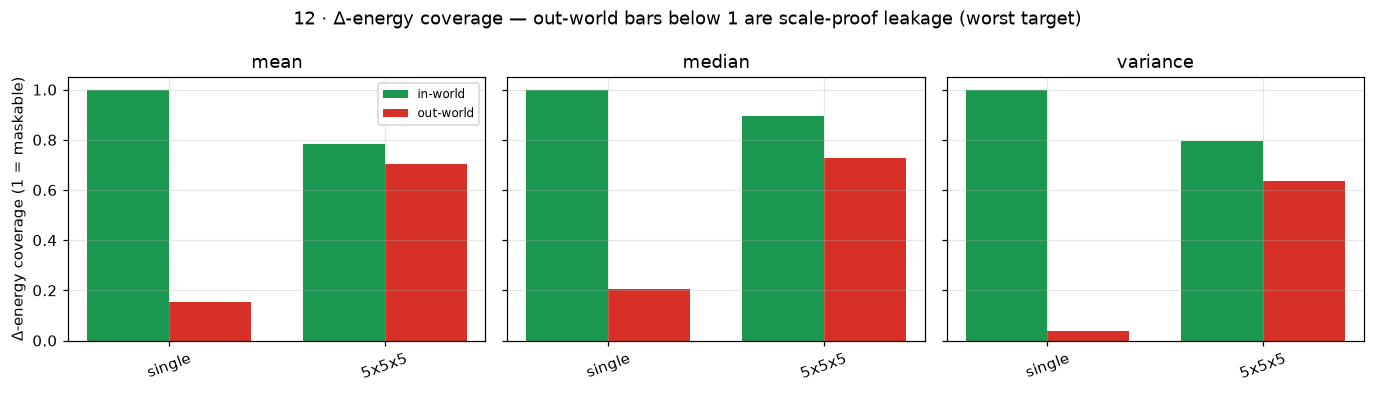

In [26]:
cc_cfg = [("single","single"), (REP_PATCH, PATCHES[REP_PATCH]), (REF_PATCH, PATCHES[REF_PATCH])]
cc_cfg = [c for i,c in enumerate(cc_cfg) if c[0] not in [x[0] for x in cc_cfg[:i]]]   # dedup
CC = []
for st in STATS:
    tgt = TGT[st]["worst"]
    for nm, ps in cc_cfg:
        gi, go, ri, ro, dv = R.two_worlds(COHORT, MASK, st, ps, 0.5, BLEND, tgt, n_build_jobs=NB_BUILD)
        CC.append(dict(stat=st, patch=nm, world="in",  coverage=ri.delta_coverage(dv)))
        CC.append(dict(stat=st, patch=nm, world="out", coverage=ro.delta_coverage(dv)))
    print(f"  coverage {st} done")
CC = pd.DataFrame(CC)
cfgs = [c[0] for c in cc_cfg]
fig, axes = plt.subplots(1, len(STATS), figsize=(4.2*len(STATS), 3.6), squeeze=False, sharey=True)
x = np.arange(len(cfgs)); w = 0.38
def _cov(s, c, world):
    v = s[(s.patch==c)&(s.world==world)].coverage
    return float(v.iloc[0]) if len(v) else np.nan
for a, st in zip(axes[0], STATS):
    s = CC[CC.stat==st]
    ins = [_cov(s, c, "in") for c in cfgs]
    out = [_cov(s, c, "out") for c in cfgs]
    a.bar(x-w/2, ins, w, label="in-world", color="#1a9850")
    a.bar(x+w/2, out, w, label="out-world", color="#d73027")
    a.set_xticks(x); a.set_xticklabels(cfgs, rotation=20); a.set_ylim(0,1.05); a.set_title(st)
    if a is axes[0][0]: a.set_ylabel("Δ-energy coverage (1 = maskable)"); a.legend(fontsize=8)
fig.suptitle("12 · Δ-energy coverage — out-world bars below 1 are scale-proof leakage (worst target)")
plt.tight_layout(); plt.show()

## Summary (reads from the run — no hard-coded conclusions)

Interpret the figures together:
- **Frontier (§3, §6):** compare where each patch size and `single` sit; the operating scale per
  statistic and the acceptable configs come from the §6 selection table (criterion adv_hi ≤ ε).
- **Overlap (§3-2):** whether overlap moves advantage at all in the tested regime.
- **k_check (§3b):** whether advantage rises as policing depth falls, and at what utility cost — the
  justification (or not) for `k_check = r`.
- **N (§3c):** whether more subjects buy privacy (prediction: roughly flat).
- **Reconstruction (§4):** reconstruction error growth vs scale, per target.
- **Inference (§5 / 5b):** hard-bar Type-1 inflation vs Option B's near-nominal FWER — the mechanism
  trade-off for the supervisor.
- **Isolated patches (§9):** whether leakage exists per-patch before assembly.
- **Blend (§10):** whether `average` leaks more than `pou_energy` (noise averaged away).
- **Number of patches (§11):** whether advantage rises with k — the direct aggregation test.
- **Δ-coverage (§12):** how much of the leak is scale-proof (out-world null space) vs aggregation
  (which §11 drives) — if out-world coverage is well below 1, no scale fully closes it.

The residual aggregation leak (advantage stays appreciable at the operating scale) is structural; a
composition-aware / formal-DP calibration is the fix, out of scope here.